# Stock Market Forecasting with PyTorch LSTM
## Economics PBL

This model returns stock prediction with a **LSTM** neural network



In [18]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

import torch
import torch.nn as nn

warnings.filterwarnings("ignore")

#i do have cuda on my device but baaki logo ke liye if they dont have it, it fallbacks to cpu
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using compute device: {device}")

# seed everything so the results dont change every time the notebook is rerun
# (train_lstm is reseeded again just before training, see the training cell)
SEED_GLOBAL = 42
np.random.seed(SEED_GLOBAL)
torch.manual_seed(SEED_GLOBAL)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED_GLOBAL)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

# style stuff
try:
    plt.style.use("seaborn-v0_8-whitegrid")
except Exception:
    pass

OUT_DIR = "eco_plots"
os.makedirs(OUT_DIR, exist_ok=True)


Using compute device: cuda


###  STEP 2: Stock Picker & Training Configuration
Edit the configuration below to choose any company (e.g. **AAPL**, **META**, **NVDA**, **MSFT**, **TSLA**, **RELIANCE.NS**, etc.) and set the number of **Epochs** for model training.


In [19]:
#listed popular stocks here (tbh idt this model works on other stocks properly, getting poor rmse for them)
#this dict is mainly for the website
AVAILABLE_STOCKS = {
    "AAPL":        {"name": "Apple Inc.",                "currency": "$", "base_price": 180.0, "volatility": 0.015},
    "META":        {"name": "Meta Platforms Inc.",       "currency": "$", "base_price": 300.0, "volatility": 0.022},
    "NVDA":        {"name": "NVIDIA Corporation",        "currency": "$", "base_price": 120.0, "volatility": 0.028},
    "MSFT":        {"name": "Microsoft Corporation",     "currency": "$", "base_price": 350.0, "volatility": 0.014},
    "AMZN":        {"name": "Amazon.com Inc.",           "currency": "$", "base_price": 150.0, "volatility": 0.018},
    "GOOGL":       {"name": "Alphabet Inc. (Google)",    "currency": "$", "base_price": 170.0, "volatility": 0.016},
    "TSLA":        {"name": "Tesla Inc.",                "currency": "$", "base_price": 220.0, "volatility": 0.032},
    "RELIANCE.NS": {"name": "Reliance Industries Ltd",   "currency": "₹", "base_price": 2500.0, "volatility": 0.012},
    "TCS.NS":      {"name": "Tata Consultancy Services", "currency": "₹", "base_price": 3500.0, "volatility": 0.011},
    "INFY.NS":     {"name": "Infosys Ltd",               "currency": "₹", "base_price": 1500.0, "volatility": 0.013},
    "^NSEI":       {"name": "NIFTY 50 Index",            "currency": "₹", "base_price": 20000.0, "volatility": 0.009},
    "^GSPC":       {"name": "S&P 500 Index",             "currency": "$", "base_price": 5000.0, "volatility": 0.009},
}

#ticker
TICKER = "TSLA"               

# 2 epochs, somehow the best epoch number is 1? and more than 10 epochs are not introducing any improvement
EPOCHS = 10     

#hyperparams
LOOKBACK_WINDOW = 60          
BATCH_SIZE = 64               # claue told me to add this
LEARNING_RATE = 1e-3          # claude told me this is an optimal learning rate for adam
PATIENCE = 10                 # as tested earlier, no gain after 10 epochs
HIDDEN_DIM = 64              
NUM_LAYERS = 2              
DROPOUT = 0.2                 
SEED = 42

#for simulating stuff, added by copilot for uhhh making the project more robust
CAPITAL = 100_000            
TC_RATE = 0.001               # transaction cost (tax and all yada yada)
SCALE_W = 100_000             # dont know what this is tbh
START_DATE = "2015-01-01"     # configurable
END_DATE = "2026-10-31"
#test val
TEST_FRAC = 0.2              
VAL_FRAC = 0.15               
# ticker selector
meta = AVAILABLE_STOCKS.get(TICKER, {
    "name": TICKER,
    "currency": "₹" if TICKER.endswith((".NS", ".BO")) else "$", #since nse stocks end with .ns
    "base_price": 100.0,
    "volatility": 0.018
})
CURRENCY = meta["currency"]
COMPANY_NAME = meta["name"]

print("=" * 60)
print(f"Selected Stock   : {TICKER} ({COMPANY_NAME})")
print(f"Currency         : {CURRENCY}")
print(f"Training Epochs  : {EPOCHS}")
print(f"Lookback Window  : {LOOKBACK_WINDOW} days")
print(f"Initial Capital  : {CURRENCY}{CAPITAL:,}")
print("=" * 60)


Selected Stock   : TSLA (Tesla Inc.)
Currency         : $
Training Epochs  : 10
Lookback Window  : 60 days
Initial Capital  : $100,000


### STEP 3: Data feeding through yfinance
Included a brownian motion fallback if yfinance is unavailable


In [20]:
#thankyou claude
def make_synthetic(ticker, n=2800):
    """Fallback generator matching the stock's profile."""
    rng = np.random.default_rng(42)
    idx = pd.bdate_range(START_DATE, periods=n)
    vol = meta.get("volatility", 0.018)
    base = meta.get("base_price", 100.0)
    r = rng.normal(0.0004, vol, n)
    price = base * np.cumprod(1 + r)
    volume = rng.lognormal(15, 0.3, n) * (1 + 50 * np.abs(r))
    return pd.DataFrame({"Close": price, "Volume": volume}, index=idx)

def load_data(ticker):
    try:
        import yfinance as yf
        print(f"Fetching live market data for {ticker} from yfinance")
        df = yf.download(ticker, start=START_DATE, end=END_DATE, auto_adjust=True, progress=False)
        if isinstance(df.columns, pd.MultiIndex):
            df.columns = df.columns.get_level_values(0)
        df = df[["Close", "Volume"]].dropna()
        if df.empty or len(df) < 100:
            raise ValueError("Insufficient data returned.")
        print(f"Successfully downloaded {len(df)} trading records for {ticker}.")
        return df, f"{ticker} ({COMPANY_NAME})"
    except Exception as e:
        print(f"Notice: Could not download {ticker} via yfinance ({e}).")
        print("Using realistic market simulation instead.")
        return make_synthetic(ticker), f"{ticker} (SIMULATED: {COMPANY_NAME})"

raw_df, stock_label = load_data(TICKER)
raw_df.tail()


Fetching live market data for TSLA from yfinance
Successfully downloaded 2975 trading records for TSLA.


Price,Close,Volume
Date,,
2026-10-26,391.619995,53090200
2026-10-27,407.459991,45333200
2026-10-28,404.220001,35598800
2026-10-29,403.299988,22858300
2026-10-30,399.809998,41737200


### STEP 4: Economics-Grounded Feature Engineering
using these features derived from eco classes:
1. **`price_change`**: Daily percentage return: $\frac{P_t - P_{t-1}}{P_{t-1}}$.
2. **`quantity_gap`**: Trading volume relative to its 10-day moving average: $\frac{Q_t}{\bar{Q}_{10}} - 1$.
3. **`price_gap`**: Distance of market price from its recent 10-day average: $\frac{P_t}{\bar{P}_{10}} - 1$ 
4. **`excess_demand`**: buyer pressure minus seller pressure:
   $$\text{Excess Demand} = \frac{\sum_{10} V_{\text{up}} - \sum_{10} V_{\text{down}}}{\sum_{10} V_{\text{total}}}$$
   - Positive ($> 0$): **Shortage** (buyers dominate)
   - Negative ($< 0$): **Surplus** (sellers dominate)
5. **`target`**: Tomorrow's percentage price return $\frac{P_{t+1} - P_t}{P_t}$.


In [21]:

def build_dataset(df):
    price = df["Close"]
    quantity = df["Volume"].clip(lower=1)

    out = pd.DataFrame(index=df.index)
    out["close"] = price
    out["price_change"] = price.pct_change()
    out["quantity_gap"] = quantity / quantity.rolling(10).mean() - 1
    out["price_gap"] = price / price.rolling(10).mean() - 1

    #thank you claude
    up_q = quantity.where(out["price_change"] > 0, 0.0)
    down_q = quantity.where(out["price_change"] < 0, 0.0)
    out["excess_demand"] = (up_q.rolling(10).sum() - down_q.rolling(10).sum()) / quantity.rolling(10).sum()

    out["target"] = out["price_change"].shift(-1)
    out = out.dropna()
    next_dates = df.index[df.index.get_indexer(out.index) + 1]
    return out, next_dates

dataset, target_dates = build_dataset(raw_df)
n_total = len(dataset)
split_idx = int(n_total * (1 - TEST_FRAC))
split_date = dataset.index[split_idx]

print(f"Dataset shape: {dataset.shape}")
dataset[["close", "price_change", "quantity_gap", "price_gap", "excess_demand", "target"]].head()


Dataset shape: (2965, 6)


,close,price_change,quantity_gap,price_gap,excess_demand,target
Date,,,,,,
2015-01-15,12.791333,-0.004256,-0.045820,-0.068561,-0.519978,0.006254
2015-01-16,12.871333,0.006254,-0.326615,-0.050642,-0.463924,-0.005905
2015-01-20,12.795333,-0.005905,-0.144586,-0.047744,-0.455112,0.024176
2015-01-21,13.104667,0.024176,-0.178187,-0.017553,-0.515837,0.025691
2015-01-22,13.441333,0.025691,-0.203434,0.012408,-0.367283,-0.001637


### Plot 1: Historical Market Price & 50-Day Moving Average
- **Blue line**: 50-day moving average
- **Narangi region**:test period


In [22]:
fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(dataset.index, dataset["close"], color="grey", lw=1, label="Market Price")
avg50 = dataset["close"].rolling(50).mean()
ax.plot(avg50.index, avg50, color="tab:blue", lw=1.5, label="50-day MA (Equilibrium Level)")
ax.axvspan(split_date, dataset.index[-1], color="orange", alpha=0.15, label="Unseen Test Period")
ax.set_yscale("log")  # log scale so the early low-price years are readable next to the recent prices
ax.set_title(f"{stock_label}: Price Trajectory & Equilibrium Trend", fontsize=12)
ax.set_ylabel(f"Price ({CURRENCY}, log scale)")
ax.legend(loc="upper left")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/01_price_history.png", dpi=150)
plt.show()


### Plot 2: Excess Demand graph
- **Upper Panel**: Closing price over the past n number of  trading days).
- **Lower Panel**: Daily excess demand ratio:
  - 🟢 **Green (> 0)**: Buyers dominate **Shortage** (upward price pressure).
  - 🔴 **Red (< 0)**: Sellers dominate **Surplus** (downward price pressure).


In [23]:
recent = dataset.iloc[-250:]
fig, ax = plt.subplots(2, 1, figsize=(13, 7), sharex=True, gridspec_kw={"height_ratios": [1.3, 1]})
ax[0].plot(recent.index, recent["close"], color="tab:blue", lw=1.3)
ax[0].set_ylabel(f"Price ({CURRENCY})")
ax[0].set_title(f"{stock_label}: Market Price (Past ~1 Year)", fontsize=11)

colors = np.where(recent["excess_demand"] >= 0, "tab:green", "tab:red")
ax[1].bar(recent.index, recent["excess_demand"], color=colors, width=1.0)
ax[1].axhline(0, color="k", lw=0.8)
ax[1].set_ylabel("Excess Demand")
ax[1].set_title("Shortage vs Surplus: Green = Buyers Dominate (Demand > Supply) | Red = Sellers Dominate (Supply > Demand)", fontsize=11)
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/02_excess_demand.png", dpi=150)
plt.show()


### Plot 3:Supply & Demand Curve Model
This theoretical diagram showcases the core economics principles:


In [24]:
def plot_microeconomic_model():
    Pd0, Ps0, m, n = 150.0, 50.0, 0.5, 0.5
    Qe = (Pd0 - Ps0) / (m + n)
    Pe = Pd0 - m * Qe
    s = 30.0
    Qe2 = (Pd0 + m * s - Ps0) / (m + n)
    Pe2 = Ps0 + n * Qe2
    cs = 0.5 * Qe * (Pd0 - Pe)
    ps = 0.5 * Qe * (Pe - Ps0)
    ed = (-1 / m) * Pe / Qe
    es = (1 / n) * Pe / Qe #all ts genuinely fried me

    Q = np.linspace(0, 220, 200)
    q1 = np.linspace(0, Qe, 100)
    fig, ax = plt.subplots(figsize=(9.5, 6.5))
    ax.plot(Q, Pd0 - m * Q, color="tab:blue", lw=2, label="Demand curve D ")
    ax.plot(Q, Ps0 + n * Q, color="tab:red", lw=2, label="Supply curve S ")
    ax.plot(Q, Pd0 + m * s - m * Q, color="tab:blue", lw=2, ls="--", label="New Demand D2 ")
    ax.fill_between(q1, Pd0 - m * q1, Pe, color="tab:blue", alpha=0.18, label=f"Consumer Surplus = {cs:.0f}")
    ax.fill_between(q1, Pe, Ps0 + n * q1, color="tab:red", alpha=0.18, label=f"Producer Surplus = {ps:.0f}")
    ax.scatter([Qe], [Pe], color="k", zorder=5)
    ax.annotate(f"Equilibrium E\nP = {Pe:.0f}, Q = {Qe:.0f}", (Qe, Pe), xytext=(Qe + 8, Pe - 28), fontsize=9)
    ax.scatter([Qe2], [Pe2], color="green", zorder=5)
    ax.annotate(f"New Equilibrium E2\nP = {Pe2:.1f}, Q = {Qe2:.0f}\n(Price rises)", (Qe2, Pe2),
                xytext=(Qe2 + 6, Pe2 + 10), fontsize=9, color="green")
    for price, text in [(75, "Shortage (price UP)"), (125, "Surplus : (Price DOWN)")]:
        qs_, qd_ = (price - Ps0) / n, (Pd0 - price) / m
        ax.annotate("", xy=(qd_, price), xytext=(qs_, price), arrowprops=dict(arrowstyle="<->", color="grey"))
        ax.text((qs_ + qd_) / 2, price + 3, text, ha="center", fontsize=9, color="dimgrey")
    ax.text(0.98, 0.04, f"Price Elasticity at E:\nDemand = {ed:.1f}\nSupply = {es:.1f}",
            transform=ax.transAxes, ha="right", va="bottom", fontsize=9,
            bbox=dict(boxstyle="round", fc="white", alpha=0.85))
    ax.set_xlabel("Quantity of Shares Traded (Q)")
    ax.set_ylabel(f"Price (P in {CURRENCY})")
    ax.set_xlim(0, 220)
    ax.set_ylim(0, 170)
    ax.set_title(" Demand, Supply, Surpluses & Elasticity", fontsize=12)
    ax.legend(loc="upper right", fontsize=8.5)
    plt.tight_layout()
    plt.savefig(f"{OUT_DIR}/03_supply_demand_illustration.png", dpi=150)
    plt.show()

plot_microeconomic_model()


### STEP 7: Dataset Preprocessing & 60-Day Sliding Windows
To prevent lookahead bias and data leakage, the scalers are fit on the training part only.
Inputs are 60-day sliding windows. The training data is split 85/15 into train/validation, in time order (no shuffling across the split).


In [25]:
FEATURES = ["price_change", "quantity_gap", "price_gap", "excess_demand"]

scaler_x = StandardScaler().fit(dataset[FEATURES].values[:split_idx])
scaler_y = StandardScaler().fit(dataset[["target"]].values[:split_idx])

X_scaled = scaler_x.transform(dataset[FEATURES].values)
y_scaled = scaler_y.transform(dataset[["target"]].values).ravel()

def make_sequences(X, y, window=LOOKBACK_WINDOW):
    xs, ys = [], []
    for i in range(window, len(X) + 1):
        xs.append(X[i - window:i])
        ys.append(y[i - 1])
    return np.array(xs, dtype=np.float32), np.array(ys, dtype=np.float32)

X_seq, y_seq = make_sequences(X_scaled, y_scaled)
end_row_indices = np.arange(LOOKBACK_WINDOW - 1, n_total)
train_mask = end_row_indices < split_idx

X_train_full, y_train_full = X_seq[train_mask], y_seq[train_mask]
X_test, y_test = X_seq[~train_mask], y_seq[~train_mask]

# Split train_full into train and validation
val_cutoff = int(len(X_train_full) * (1 - VAL_FRAC))
X_train, y_train = X_train_full[:val_cutoff], y_train_full[:val_cutoff]
X_val, y_val = X_train_full[val_cutoff:], y_train_full[val_cutoff:]

print(f"Training sequences   : {X_train.shape} (X) | {y_train.shape} (y)")
print(f"Validation sequences : {X_val.shape} (X)   | {y_val.shape} (y)")
print(f"Testing sequences    : {X_test.shape} (X)  | {y_test.shape} (y)")


Training sequences   : (1966, 60, 4) (X) | (1966,) (y)
Validation sequences : (347, 60, 4) (X)   | (347,) (y)
Testing sequences    : (593, 60, 4) (X)  | (593,) (y)


### STEP 8: LSTM training
The model architecture:
 **2 LSTM Layers** with `hidden_dim = 64` and `dropout = 0.2`.
 **RMSE Tracking**: At every epoch, both **Train RMSE** and **Val RMSE** are printed in standardized and unscaled % units 


In [26]:
class LSTMModel(nn.Module):
    def __init__(self, n_features, hidden_dim=HIDDEN_DIM, num_layers=NUM_LAYERS, dropout=DROPOUT):
        super().__init__()
        self.lstm = nn.LSTM(n_features, hidden_dim, num_layers, batch_first=True, dropout=dropout)
        self.head = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, 1)
        )

    def forward(self, x):
        out, _ = self.lstm(x)
        return self.head(out[:, -1, :]).squeeze(-1)

def batch_generator(X, y, batch_size=BATCH_SIZE, shuffle=True):
    indices = np.random.permutation(len(X)) if shuffle else np.arange(len(X))
    for i in range(0, len(X), batch_size):
        b_idx = indices[i:i + batch_size]
        yield torch.tensor(X[b_idx]).to(device), torch.tensor(y[b_idx]).to(device)

def predict(model, X):
    model.eval()
    preds = []
    with torch.no_grad():
        for xb, _ in batch_generator(X, np.zeros(len(X), dtype=np.float32), batch_size=BATCH_SIZE, shuffle=False):
            preds.append(model(xb).cpu().numpy())
    return np.concatenate(preds)

def train_lstm(X_tr, y_tr, X_v, y_v, epochs=EPOCHS):
    model = LSTMModel(len(FEATURES)).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    criterion = nn.MSELoss()
    best_loss = np.inf
    best_weights = None
    patience_counter = 0
    train_rmse_hist, val_rmse_hist = [], []

    target_scale = float(scaler_y.scale_[0])  #conversion to scaled and unscaled ion really get it ngl

    print(f"🚀 Training LSTM for {epochs} epochs (Early Stopping Patience = {PATIENCE})...")
    print("-" * 75)
    print(f"{'Epoch':^8} | {'Train MSE':^11} | {'Val MSE':^11} | {'Train RMSE (%)':^16} | {'Val RMSE (%)':^16}")
    print("-" * 75)

    for epoch in range(1, epochs + 1):
        model.train()
        batch_losses = []
        for xb, yb in batch_generator(X_tr, y_tr, shuffle=True):
            optimizer.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            batch_losses.append(loss.item())

        train_mse = float(np.mean(batch_losses))
        val_preds = predict(model, X_v)
        val_mse = float(np.mean((val_preds - y_v) ** 2))
        
        train_rmse = float(np.sqrt(train_mse))
        val_rmse = float(np.sqrt(val_mse))
        
        train_rmse_hist.append(train_rmse * target_scale * 100)
        val_rmse_hist.append(val_rmse * target_scale * 100)

        if epoch % 5 == 0 or epoch == 1 or epoch == epochs:
            print(f"{epoch:^8d} | {train_mse:^11.4f} | {val_mse:^11.4f} | {train_rmse * target_scale * 100:^16.4f}% | {val_rmse * target_scale * 100:^16.4f}%")

        if val_mse < best_loss:
            best_loss = val_mse
            patience_counter = 0
            best_weights = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            patience_counter += 1
            if patience_counter >= PATIENCE:
                print(f"Early stopping at epoch {epoch}: Validation loss stopped improving.")
                break

    print("-" * 75)
    if best_weights is not None:
        model.load_state_dict(best_weights)

    return model, train_rmse_hist, val_rmse_hist

# reseed right before training so rerunning just this cell gives the same model
torch.manual_seed(SEED)
np.random.seed(SEED)
trained_model, tr_rmse_curve, val_rmse_curve = train_lstm(X_train, y_train, X_val, y_val, epochs=EPOCHS)


🚀 Training LSTM for 10 epochs (Early Stopping Patience = 10)...
---------------------------------------------------------------------------
 Epoch   |  Train MSE  |   Val MSE   |  Train RMSE (%)  |   Val RMSE (%)  
---------------------------------------------------------------------------
   1     |   1.0478    |   0.8100    |      3.6320     % |      3.1935     %
   5     |   1.0512    |   0.8071    |      3.6379     % |      3.1877     %
   10    |   1.0529    |   0.8068    |      3.6409     % |      3.1872     %
---------------------------------------------------------------------------


### Plot 4: Training vs Validation Learning Curve (RMSE)
- Displays Root Mean Squared Error (in percentage return units) across all epochs.
- The vertical dashed line marks the checkpoint where validation RMSE reached its minimum (best model weights).
- ~~its not working properly, it should be ignored as of now~~ NOW ITS WORKING


In [27]:
fig, ax = plt.subplots(figsize=(8.5, 4.5))
ax.plot(tr_rmse_curve, label="Training RMSE (% return)", color="tab:blue")
ax.plot(val_rmse_curve, label="Validation RMSE (% return)", color="tab:orange")
best_epoch = int(np.argmin(val_rmse_curve))
ax.axvline(best_epoch, color="k", ls="--", lw=0.8, label=f"Best Model (Epoch {best_epoch + 1})")
ax.set_title("LSTM Learning Curve: RMSE across Training Epochs", fontsize=11)
ax.set_xlabel("Epoch")
ax.set_ylabel("RMSE (% Daily Return)")
ax.legend()
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/04_training_curve.png", dpi=150)
plt.show()


### STEP 9: Out-of-Sample Forecast Evaluation & Test RMSE
We unscale predictions to calculate tomorrow's predicted prices:
$$\hat{P}_{t+1} = P_t \times (1 + \hat{r}_{t+1})$$
And compare them directly against actual market prices $P_{t+1}$ and the **Naive Baseline** ($P_{t+1} = P_t$).


In [28]:
# Inverse transform scaled test predictions
pred_returns = scaler_y.inverse_transform(predict(trained_model, X_test).reshape(-1, 1)).ravel()
actual_returns = scaler_y.inverse_transform(y_test.reshape(-1, 1)).ravel()

test_row_indices = end_row_indices[~train_mask]
test_dates = target_dates[test_row_indices]
today_prices = dataset["close"].values[test_row_indices]

actual_prices = today_prices * (1 + actual_returns)
predicted_prices = today_prices * (1 + pred_returns)
naive_prices = today_prices.copy()

# Test Set RMSE Metrics
rmse = lambda actual, pred: float(np.sqrt(np.mean((actual - pred) ** 2)))
mae = lambda actual, pred: float(np.mean(np.abs(actual - pred)))

return_rmse_lstm = rmse(actual_returns, pred_returns) * 100
return_rmse_naive = rmse(actual_returns, 0) * 100
price_rmse_lstm = rmse(actual_prices, predicted_prices)
price_rmse_naive = rmse(actual_prices, naive_prices)

print("=" * 60)
print(f"TEST SET RMSE EVALUATION: {stock_label}")
print("=" * 60)
print(f"Daily Return RMSE : LSTM {return_rmse_lstm:.4f}% vs Naive {return_rmse_naive:.4f}%")
print(f"Price Level RMSE  : LSTM {CURRENCY}{price_rmse_lstm:.2f} vs Naive {CURRENCY}{price_rmse_naive:.2f}")
print("=" * 60)


TEST SET RMSE EVALUATION: TSLA (Tesla Inc.)
Daily Return RMSE : LSTM 3.7599% vs Naive 3.7547%
Price Level RMSE  : LSTM $12.19 vs Naive $12.15


###  Plot 5: Test Period Forecast vs. Actual Prices
- **Top Panel**: Full test horizon comparing Actual Price (blue) with LSTM Forecast (orange).
- **Bottom Panel**: Zoom on the last 90 trading days comparing Actual vs. LSTM vs. Naive Baseline.


In [29]:
fig, ax = plt.subplots(2, 1, figsize=(13, 9), gridspec_kw={"height_ratios": [1.2, 1]})
train_dates = dataset.index[:split_idx + 1]
ax[0].plot(train_dates, dataset["close"].values[:split_idx + 1], color="grey", lw=1, label="Past Price (Training Period)")
ax[0].plot(test_dates, actual_prices, color="tab:blue", lw=1.3, label="Actual Price (Test Period)")
ax[0].plot(test_dates, predicted_prices, color="tab:orange", lw=1.1, alpha=0.9, label="LSTM Next-Day Forecast")
ax[0].axvline(test_dates[0], color="k", ls=":", lw=1, label="Test Boundary")
ax[0].set_yscale("log")  # log scale, same reason as plot 1
ax[0].set_title(f"{stock_label}: Test Period Forecast vs Actual Trajectory", fontsize=12)
ax[0].set_ylabel(f"Price ({CURRENCY}, log scale)")
ax[0].legend(loc="upper left")

z = min(90, len(test_dates))
ax[1].plot(test_dates[-z:], actual_prices[-z:], "o-", color="tab:blue", ms=3, lw=1.2, label="Actual Price")
ax[1].plot(test_dates[-z:], predicted_prices[-z:], "s-", color="tab:orange", ms=3, lw=1.1, label="LSTM Forecast")
ax[1].plot(test_dates[-z:], naive_prices[-z:], "--", color="green", lw=1, label="Naive Baseline: Tomorrow = Today")
ax[1].set_title(f"Detailed Zoom (Last {z} Trading Days): LSTM vs Naive Baseline", fontsize=11)
ax[1].set_ylabel(f"Price ({CURRENCY})")
ax[1].legend()
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/05_predicted_vs_actual_price.png", dpi=150)
plt.show()


### Plot 6: Forecast Error Distribution & Scatter Plot
- **Left Panel**: Dollar residual error over time ($\hat{P}_t - P_t$).
- **Right Panel**: Scatter of predicted % return vs actual % return against the 45° line of perfect prediction.



In [30]:
#i dont really get this graph tbh, i just asked claude what more should i add. 
err = predicted_prices - actual_prices
hit_rate = np.sign(pred_returns) == np.sign(actual_returns)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
ax[0].plot(test_dates, err, color="tab:purple", lw=0.8)
ax[0].axhline(0, color="k", lw=0.8)
ax[0].set_title(f"Forecast Error: Predicted - Actual ({CURRENCY})", fontsize=11)
ax[0].set_ylabel(f"Error ({CURRENCY})")

ax[1].scatter(pred_returns * 100, actual_returns * 100, s=9, alpha=0.4, color="tab:blue")
lim = max(np.abs(actual_returns).max(), np.abs(pred_returns).max()) * 100
ax[1].plot([-lim, lim], [-lim, lim], "k--", lw=1, label="Perfect Forecast (45° line)")
ax[1].axhline(0, color="grey", lw=0.6)
ax[1].axvline(0, color="grey", lw=0.6)
ax[1].set_xlabel("Predicted Daily Return (%)")
ax[1].set_ylabel("Actual Daily Return (%)")
ax[1].set_title(f"Predicted vs Actual Return (Direction Accuracy: {hit_rate.mean():.1%})", fontsize=11)
ax[1].legend()
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/06_forecast_errors.png", dpi=150)
plt.show()


###  STEP 10: Firm Theory: Backtesting Revenue, Costs & Profit
firm operates only when **Marginal Revenue ($MR$) > Marginal Cost ($MC$)**.
- **Total Revenue ($TR$)**: Gross trading gains.
- **Total Cost ($TC$)**: transaction frictions such as tax and small service cuts ($TC = \text{cost per trade} \times \text{trades}$).
- **Profit ($\pi$)**: $\pi = TR - TC$.


In [31]:
def make_strategy_position(pred_ret, cost_multiplier=2.0, volatility_multiplier=0.15, strategy_mode="active"):
    """Use a cost-aware long/cash rule with a volatility buffer."""
    pred_ret = np.asarray(pred_ret, dtype=float)
    if len(pred_ret) == 0:
        return np.array([], dtype=float), np.array([], dtype=float)
    if strategy_mode == "buy_and_hold":
        return np.ones(len(pred_ret), dtype=float), np.full(len(pred_ret), 0.0)

    recent_vol = np.full(len(pred_ret), np.nan, dtype=float)
    for i in range(len(pred_ret)):
        history = pred_ret[max(0, i - 19):i + 1]
        recent_vol[i] = float(np.std(history, ddof=1)) if len(history) > 1 else 0.0

    entry_threshold = np.maximum(cost_multiplier * TC_RATE, volatility_multiplier * recent_vol)
    position = np.zeros(len(pred_ret), dtype=float)
    for i, forecast in enumerate(pred_ret):
        if i > 0:
            position[i] = position[i - 1]
        if position[i] == 0.0 and forecast > entry_threshold[i]:
            position[i] = 1.0
        elif position[i] == 1.0 and forecast <= 0.0:
            position[i] = 0.0
    return position, entry_threshold


def select_strategy_params(pred_ret, true_ret):
    candidates = [("active", c, v) for c in (1.0, 2.0, 3.0, 4.0) for v in (0.0, 0.1, 0.2, 0.3)]
    candidates.append(("buy_and_hold", 0.0, 0.0))
    best_score, best_params = -np.inf, candidates[0]
    for strategy_mode, cost_multiplier, volatility_multiplier in candidates:
        position, _ = make_strategy_position(pred_ret, cost_multiplier, volatility_multiplier, strategy_mode)
        trades = np.abs(np.diff(position, prepend=0.0))
        wealth = CAPITAL + np.cumsum(CAPITAL * position * true_ret - CAPITAL * TC_RATE * trades)
        peak = np.maximum.accumulate(wealth)
        drawdown = float(np.max((peak - wealth) / peak))
        score = float(wealth[-1]) - CAPITAL * drawdown
        if score > best_score:
            best_score, best_params = score, (strategy_mode, cost_multiplier, volatility_multiplier)
    return {"strategy_mode": best_params[0], "cost_multiplier": best_params[1], "volatility_multiplier": best_params[2]}


def backtest_strategy(dates, actual_ret, pred_ret, strategy_params=None):
    strategy_params = strategy_params or {}
    position, entry_threshold = make_strategy_position(
        pred_ret, strategy_params.get("cost_multiplier", 2.0),
        strategy_params.get("volatility_multiplier", 0.15),
        strategy_params.get("strategy_mode", "active")
    )
    trade_signals = np.abs(np.diff(position, prepend=0.0))
    # fixed position size = CAPITAL every day (profits are not reinvested), so wealth here is simple, not compounded
    # (the walk-forward section below does compound)
    daily_gross = CAPITAL * position * actual_ret
    daily_cost = CAPITAL * TC_RATE * trade_signals

    def summarize(gross, cost, trades):
        tr = float(gross.sum())
        tc = float(cost.sum())
        return {
            "tr": tr, "tc": tc, "profit": tr - tc, "trades": int(trades.sum()),
            "cum_tr": np.cumsum(gross), "cum_tc": np.cumsum(cost),
            "wealth": CAPITAL + np.cumsum(gross - cost)
        }

    strat = summarize(daily_gross, daily_cost, trade_signals)
    bh_trades = np.zeros_like(actual_ret)
    bh_trades[0] = 1
    bh = summarize(CAPITAL * actual_ret, CAPITAL * TC_RATE * bh_trades, bh_trades)

    # Plot 7
    fig, ax = plt.subplots(3, 1, figsize=(13, 11), sharex=True, gridspec_kw={"height_ratios": [1.3, 1.3, 0.6]})
    ax[0].plot(dates, strat["cum_tr"], color="tab:green", lw=1.6, label="Total Revenue TR (Gross Gains)")
    ax[0].plot(dates, strat["cum_tc"], color="tab:red", lw=1.6, label="Total Cost TC (Trading Frictions)")
    ax[0].fill_between(dates, strat["cum_tc"], strat["cum_tr"], where=strat["cum_tr"] >= strat["cum_tc"],
                        color="green", alpha=0.15, label="Profit (TR > TC)")
    ax[0].fill_between(dates, strat["cum_tc"], strat["cum_tr"], where=strat["cum_tr"] < strat["cum_tc"],
                        color="red", alpha=0.15, label="Loss (TR < TC)")
    ax[0].axhline(0, color="k", lw=0.6)
    ax[0].set_title("Trading Strategy as a Firm: Total Revenue vs Total Cost (Profit = TR - TC)", fontsize=12)
    ax[0].set_ylabel(f"Amount ({CURRENCY})")
    ax[0].legend(fontsize=8.5)

    ax[1].plot(dates, strat["wealth"], color="tab:orange", lw=1.6, label="LSTM Active Strategy")
    ax[1].plot(dates, bh["wealth"], color="tab:blue", lw=1.6, label="Buy & Hold (Passive Benchmark)")
    ax[1].axhline(CAPITAL, color="k", ls="--", lw=0.8, label="Initial Capital")
    ax[1].set_title(f"Cumulative Wealth from {CURRENCY}{CAPITAL:,} during Test Horizon", fontsize=12)
    ax[1].set_ylabel(f"Wealth ({CURRENCY})")
    ax[1].legend(fontsize=8.5)

    ax[2].fill_between(dates, position, 0, step="post", color="tab:orange", alpha=0.6)
    ax[2].set_yticks([0, 1])
    ax[2].set_yticklabels(["Cash", "Hold Stock"])
    ax[2].set_title(f"Cost-aware Allocation ({strat['trades']} trades, entry threshold averages {entry_threshold.mean() * 100:.2f}%)", fontsize=11)
    plt.tight_layout()
    plt.savefig(f"{OUT_DIR}/07_revenue_cost_profit.png", dpi=150)
    plt.show()

    strat["strategy"] = "Validation-adaptive LSTM (long/cash)"
    strat["entry_threshold_pct"] = round(float(entry_threshold.mean()) * 100, 4)
    return strat, bh

val_pred_returns = scaler_y.inverse_transform(predict(trained_model, X_val).reshape(-1, 1)).ravel()
val_actual_returns = scaler_y.inverse_transform(y_val.reshape(-1, 1)).ravel()
strategy_params = select_strategy_params(val_pred_returns, val_actual_returns)
print("Selected validation strategy parameters:", strategy_params)
strat_results, bh_results = backtest_strategy(test_dates, actual_returns, pred_returns, strategy_params)


Selected validation strategy parameters: {'strategy_mode': 'active', 'cost_multiplier': 2.0, 'volatility_multiplier': 0.0}


### STEP 11: Investor Utility Theory & Diminishing Marginal Utility
- **Utility Function**: $$U(W) = \sqrt{\frac{W}{C}}$$
- **Marginal Utility**: $$MU(W) = \frac{dU}{dW} = \frac{1}{2\sqrt{W \cdot C}} > 0, \quad \frac{d^2U}{dW^2} < 0$$
- Concavity explains **risk aversion**: losing an amount destroys more utility than gaining the same amount creates.


In [32]:
def plot_utility_analysis(w_start, w_strat, w_bh):
    u = lambda w: np.sqrt(np.asarray(w) / SCALE_W)
    mu = lambda w: 0.5 / np.sqrt(np.asarray(w) * SCALE_W)  # dU/dW = 1/(2*sqrt(W*C)), same as the formula in the markdown

    pts = [("Initial Capital", w_start, "k"), ("LSTM Strategy", w_strat, "tab:orange"), ("Buy & Hold", w_bh, "tab:blue")]
    lo = min(0.6 * w_start, 0.9 * min(w_strat, w_bh))
    hi = 1.15 * max(w_start, w_strat, w_bh)
    W = np.linspace(lo, hi, 300)

    step = 0.1 * w_start
    gain_u = float(u(w_start + step) - u(w_start))
    loss_u = float(u(w_start) - u(w_start - step))

    fig, ax = plt.subplots(2, 1, figsize=(10, 8.5), sharex=True)
    ax[0].plot(W, u(W), color="tab:green", lw=2)
    for name, w, c in pts:
        ax[0].scatter([w], [float(u(w))], color=c, s=70, zorder=5,
                      label=f"{name}: {CURRENCY}{w:,.0f}, TU = {float(u(w)):.3f}")
    ax[0].set_ylabel("Total Utility TU (utils)")
    ax[0].set_title("Total Utility: Concave Shape Models Risk Aversion", fontsize=11)
    ax[0].legend(fontsize=8.5, loc="lower right")

    ax[1].plot(W, mu(W), color="tab:purple", lw=2)
    for name, w, c in pts:
        ax[1].scatter([w], [float(mu(w))], color=c, s=70, zorder=5)
    ax[1].set_xlabel(f"Wealth W ({CURRENCY})")
    ax[1].set_ylabel(f"Marginal Utility MU (utils per {CURRENCY})")
    ax[1].set_title("Diminishing Marginal Utility: Incremental Utility Decreases with Wealth", fontsize=11)
    ax[1].text(0.98, 0.95,
               f"+{CURRENCY}{step:,.0f} gain adds {gain_u:.4f} utils\n-{CURRENCY}{step:,.0f} loss destroys {loss_u:.4f} utils\n"
               "Key Insight: Downside risk hurts more than equal upside rewards!",
               transform=ax[1].transAxes, ha="right", va="top", fontsize=9,
               bbox=dict(boxstyle="round", fc="white", alpha=0.85))
    plt.tight_layout()
    plt.savefig(f"{OUT_DIR}/08_utility.png", dpi=150)
    plt.show()

    delta_u_strat = float(u(w_strat) - u(w_start))
    delta_u_bh = float(u(w_bh) - u(w_start))
    return delta_u_strat, delta_u_bh

du_strat, du_bh = plot_utility_analysis(CAPITAL, strat_results["wealth"][-1], bh_results["wealth"][-1])


### STEP 12:Conclusions


In [33]:
# Embedded project modules: no local .py imports are required.

# removed matplotlib.use("Agg") from here, switching backend mid-notebook can stop inline plots from showing.
# (keep Agg in plots.py for the flask app, the server has no display)
from sklearn.ensemble import RandomForestClassifier

"""Configuration: Stock catalog and default hyperparameters."""

EMBEDDED_AVAILABLE_STOCKS = {
    "AAPL":        {"name": "Apple Inc.",                "currency": "$", "base_price": 180.0, "volatility": 0.015},
    "META":        {"name": "Meta Platforms Inc.",       "currency": "$", "base_price": 300.0, "volatility": 0.022},
    "NVDA":        {"name": "NVIDIA Corporation",       "currency": "$", "base_price": 120.0, "volatility": 0.028},
    "MSFT":        {"name": "Microsoft Corporation",    "currency": "$", "base_price": 350.0, "volatility": 0.014},
    "AMZN":        {"name": "Amazon.com Inc.",          "currency": "$", "base_price": 150.0, "volatility": 0.018},
    "GOOGL":       {"name": "Alphabet Inc. (Google)",   "currency": "$", "base_price": 170.0, "volatility": 0.016},
    "TSLA":        {"name": "Tesla Inc.",               "currency": "$", "base_price": 220.0, "volatility": 0.032},
    "RELIANCE.NS": {"name": "Reliance Industries Ltd",  "currency": "₹", "base_price": 2500.0, "volatility": 0.012},
    "TCS.NS":      {"name": "Tata Consultancy Services","currency": "₹", "base_price": 3500.0, "volatility": 0.011},
    "INFY.NS":     {"name": "Infosys Ltd",              "currency": "₹", "base_price": 1500.0, "volatility": 0.013},
    "^NSEI":       {"name": "NIFTY 50 Index",           "currency": "₹", "base_price": 20000.0,"volatility": 0.009},
    "^GSPC":       {"name": "S&P 500 Index",            "currency": "$", "base_price": 5000.0, "volatility": 0.009},
}

# Model architecture defaults
EMBEDDED_LOOKBACK_WINDOW = 60
EMBEDDED_HIDDEN_DIM = 64
EMBEDDED_NUM_LAYERS = 2
EMBEDDED_DROPOUT = 0.2
EMBEDDED_BATCH_SIZE = 64
EMBEDDED_LEARNING_RATE = 1e-3
EMBEDDED_PATIENCE = 10
EMBEDDED_SEED = 42

# Data split
EMBEDDED_TEST_FRAC = 0.2
EMBEDDED_VAL_FRAC = 0.15

# Trading economics
EMBEDDED_TC_RATE = 0.001
EMBEDDED_SCALE_W = 100_000

# rough annual return on a safe asset (the opportunity cost of holding the stock), picked by the benchmark ticker (edit if needed)
EMBEDDED_RF_ANNUAL = {"^NSEI": 0.065, "^GSPC": 0.04}

# Feature columns
EMBEDDED_FEATURES = [
    "price_change", "quantity_gap", "price_gap", "excess_demand",
    "momentum_5", "momentum_10", "momentum_20", "momentum_50",
    "volatility_5", "volatility_10", "volatility_20", "volatility_50",
    "rsi_14", "volume_momentum", "drawdown_50", "ma_slope_20",
    "market_return", "relative_strength_20", "market_trend",
    "market_volatility",
]


def embedded_get_stock_meta(ticker):
    """Get metadata for a ticker symbol."""
    if ticker in EMBEDDED_AVAILABLE_STOCKS:
        return EMBEDDED_AVAILABLE_STOCKS[ticker]
    curr = "₹" if ticker.endswith((".NS", ".BO")) else "$"
    return {"name": ticker, "currency": curr, "base_price": 100.0, "volatility": 0.018}


"""Data loading (Yahoo Finance + synthetic fallback) and feature engineering."""

import numpy as np
import pandas as pd


def embedded_make_synthetic(ticker, start_date, n=2800):
    """Generate realistic simulated market data using geometric Brownian motion."""
    meta = embedded_get_stock_meta(ticker)
    rng = np.random.default_rng(EMBEDDED_SEED)
    idx = pd.bdate_range(start_date, periods=n)
    vol = meta.get("volatility", 0.018)
    base = meta.get("base_price", 100.0)
    r = rng.normal(0.0004, vol, n)
    price = base * np.cumprod(1 + r)
    volume = rng.lognormal(15, 0.3, n) * (1 + 50 * np.abs(r))
    return pd.DataFrame({"Close": price, "Volume": volume}, index=idx)


def embedded_load_data(ticker, start_date, end_date):
    """Download real market data from Yahoo Finance; fall back to synthetic if unavailable.

    Returns: (df, label_string, is_simulated_bool)
    """
    meta = embedded_get_stock_meta(ticker)
    label = f"{ticker} ({meta['name']})"
    try:
        import yfinance as yf
        df = yf.download(ticker, start=start_date, end=end_date,
                         auto_adjust=True, progress=False)
        if isinstance(df.columns, pd.MultiIndex):
            df.columns = df.columns.get_level_values(0)
        df = df[["Close", "Volume"]].dropna()
        if df.empty or len(df) < 80:
            raise ValueError("Insufficient data")
        return df, label, False
    except Exception:
        df = embedded_make_synthetic(ticker, start_date)
        return df, f"{ticker} (SIMULATED: {meta['name']})", True


def embedded_build_dataset(df, benchmark=None, horizon=5, tc_rate=0.001):
    """Build causal features, classification targets, and regression targets.

    Works robustly whether a market benchmark is supplied or not.
    """
    price = df["Close"]
    quantity = df["Volume"].clip(lower=1)

    out = pd.DataFrame(index=df.index)
    out["close"] = price
    out["price_change"] = price.pct_change()
    out["quantity_gap"] = quantity / quantity.rolling(10).mean() - 1
    out["price_gap"] = price / price.rolling(10).mean() - 1

    up_q = quantity.where(out["price_change"] > 0, 0.0)
    down_q = quantity.where(out["price_change"] < 0, 0.0)
    out["excess_demand"] = (
        (up_q.rolling(10).sum() - down_q.rolling(10).sum())
        / quantity.rolling(10).sum()
    )

    for window in (5, 10, 20, 50):
        out[f"momentum_{window}"] = price / price.shift(window) - 1
        out[f"volatility_{window}"] = out["price_change"].rolling(window).std()

    gain = out["price_change"].clip(lower=0).rolling(14).mean()
    loss = out["price_change"].clip(upper=0).abs().rolling(14).mean().replace(0, np.nan)
    out["rsi_14"] = 100 - (100 / (1 + (gain / loss).fillna(1.0)))
    out["volume_momentum"] = quantity / quantity.rolling(20).mean() - 1
    out["drawdown_50"] = price / price.rolling(50).max() - 1
    out["ma_slope_20"] = price.rolling(20).mean().pct_change(5)

    # Robust benchmark handling
    if benchmark is None or (isinstance(benchmark, (pd.Series, pd.DataFrame)) and (benchmark.dropna().empty or (benchmark == 0).all())):
        # If no benchmark is provided, use a 50-day smoothed moving average of the asset as the market baseline
        benchmark = price.rolling(50, min_periods=1).mean()

    benchmark_series = benchmark.reindex(df.index).ffill().bfill()
    benchmark_return = benchmark_series.pct_change().fillna(0.0)
    out["market_return"] = benchmark_return
    out["relative_strength_20"] = (out["momentum_20"] - benchmark_return.rolling(20).sum()).fillna(0.0)
    b_ma50 = benchmark_series.rolling(50, min_periods=1).mean()
    out["market_trend"] = (benchmark_series / b_ma50.replace(0, np.nan) - 1).fillna(0.0)
    out["market_volatility"] = benchmark_return.rolling(20, min_periods=1).std().fillna(0.0)

    # Dynamic market regime classification
    vol_median = out["market_volatility"].rolling(100, min_periods=20).median().fillna(0.01)
    out["regime"] = np.select(
        [
            out["market_trend"] < -0.02,
            out["market_volatility"] > vol_median * 1.25,
            out["market_trend"] > 0.01,
        ],
        ["defensive", "high_volatility", "trend"],
        default="neutral",
    )

    # Forward horizon returns and excess return target
    out["forward_return"] = price.shift(-horizon) / price - 1
    out["market_forward_return"] = benchmark_series.shift(-horizon) / benchmark_series - 1
    out["excess_forward_return"] = out["forward_return"] - out["market_forward_return"]
    out["target"] = (out["excess_forward_return"] > 2 * tc_rate).astype(float)

    # 1-day percentage change target for single-day regression
    out["target_return"] = out["price_change"].shift(-1)

    out = out.replace([np.inf, -np.inf], np.nan).dropna()
    target_dates = df.index[df.index.get_indexer(out.index) + horizon]
    return out, target_dates

"""PyTorch LSTM model architecture, training loop, and prediction."""

import numpy as np
import torch
import torch.nn as nn

torch.manual_seed(EMBEDDED_SEED)
np.random.seed(EMBEDDED_SEED)
EMBEDDED_DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")


class embedded_LSTMModel(nn.Module):
    def __init__(self, n_features, hidden_dim=EMBEDDED_HIDDEN_DIM,
                 num_layers=EMBEDDED_NUM_LAYERS, dropout=EMBEDDED_DROPOUT):
        super().__init__()
        self.lstm = nn.LSTM(n_features, hidden_dim, num_layers,
                            batch_first=True, dropout=dropout)
        self.head = nn.Sequential(nn.Dropout(dropout), nn.Linear(hidden_dim, 1))

    def forward(self, x):
        out, _ = self.lstm(x)
        return self.head(out[:, -1, :]).squeeze(-1)


class embedded_LSTMClassifier(nn.Module):
    """LSTM classifier for whether a forward excess return clears costs."""

    def __init__(self, n_features):
        super().__init__()
        self.lstm = nn.LSTM(n_features, EMBEDDED_HIDDEN_DIM, EMBEDDED_NUM_LAYERS,
                            batch_first=True, dropout=EMBEDDED_DROPOUT)
        self.head = nn.Sequential(nn.Dropout(EMBEDDED_DROPOUT), nn.Linear(EMBEDDED_HIDDEN_DIM, 1))

    def forward(self, x):
        out, _ = self.lstm(x)
        return self.head(out[:, -1, :]).squeeze(-1)


def embedded_make_sequences(X, y, window):
    """Create sliding-window input/target pairs."""
    xs, ys = [], []
    for i in range(window, len(X) + 1):
        xs.append(X[i - window:i])
        ys.append(y[i - 1])
    return np.array(xs, dtype=np.float32), np.array(ys, dtype=np.float32)


def _batch_gen(X, y, shuffle):
    idx = np.random.permutation(len(X)) if shuffle else np.arange(len(X))
    for i in range(0, len(X), EMBEDDED_BATCH_SIZE):
        j = idx[i:i + EMBEDDED_BATCH_SIZE]
        yield torch.tensor(X[j]).to(EMBEDDED_DEVICE), torch.tensor(y[j]).to(EMBEDDED_DEVICE)


def embedded_predict(model, X):
    """Run inference on a set of sequences."""
    model.eval()
    preds = []
    with torch.no_grad():
        for xb, _ in _batch_gen(X, np.zeros(len(X), dtype=np.float32), False):
            preds.append(model(xb).cpu().numpy())
    return np.concatenate(preds)


def embedded_train_lstm(X_tr, y_tr, X_v, y_v, epochs, target_scale):
    """Train LSTM and return (model, metrics_dict).

    *target_scale* is scaler_y.scale_[0], used to convert scaled RMSE
    back to percentage-return units for display.
    """
    model = embedded_LSTMModel(len(EMBEDDED_FEATURES)).to(EMBEDDED_DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=EMBEDDED_LEARNING_RATE)
    criterion = nn.MSELoss()
    best_loss, best_weights, wait = np.inf, None, 0
    train_rmse_hist, val_rmse_hist = [], []

    for epoch in range(1, epochs + 1):
        model.train()
        batch_losses = []
        for xb, yb in _batch_gen(X_tr, y_tr, True):
            opt.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
            batch_losses.append(loss.item())

        train_mse = float(np.mean(batch_losses))
        val_preds = embedded_predict(model, X_v)
        val_mse = float(np.mean((val_preds - y_v) ** 2))

        train_rmse_hist.append(round(float(np.sqrt(train_mse)) * target_scale * 100, 4))
        val_rmse_hist.append(round(float(np.sqrt(val_mse)) * target_scale * 100, 4))

        if val_mse < best_loss:
            best_loss, wait = val_mse, 0
            best_weights = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
            if wait >= EMBEDDED_PATIENCE:
                break

    if best_weights is not None:
        model.load_state_dict(best_weights)

    best_epoch = int(np.argmin(val_rmse_hist))
    return model, {
        "epochs_run": len(train_rmse_hist),
        "best_epoch": best_epoch + 1,
        "train_rmse": train_rmse_hist,
        "val_rmse": val_rmse_hist,
        "final_train_rmse": train_rmse_hist[-1],
        "best_val_rmse": val_rmse_hist[best_epoch],
    }


def embedded_train_lstm_classifier(X_tr, y_tr, X_v, y_v, epochs):
    """Train a binary LSTM with validation early stopping."""
    classifier = embedded_LSTMClassifier(X_tr.shape[-1]).to(EMBEDDED_DEVICE)
    optimizer = torch.optim.Adam(classifier.parameters(), lr=EMBEDDED_LEARNING_RATE)
    criterion = nn.BCEWithLogitsLoss()
    best_loss, best_weights, wait = np.inf, None, 0
    for _ in range(max(1, epochs)):
        classifier.train()
        for xb, yb in _batch_gen(X_tr, y_tr.astype(np.float32), True):
            optimizer.zero_grad()
            loss = criterion(classifier(xb), yb)
            loss.backward()
            nn.utils.clip_grad_norm_(classifier.parameters(), 1.0)
            optimizer.step()
        classifier.eval()
        with torch.no_grad():
            val_x = torch.tensor(X_v, dtype=torch.float32).to(EMBEDDED_DEVICE)
            val_y = torch.tensor(y_v, dtype=torch.float32).to(EMBEDDED_DEVICE)
            val_loss = float(criterion(classifier(val_x), val_y).item())
        if val_loss < best_loss:
            best_loss, wait = val_loss, 0
            best_weights = {k: v.clone() for k, v in classifier.state_dict().items()}
        else:
            wait += 1
            if wait >= EMBEDDED_PATIENCE:
                break
    if best_weights is not None:
        classifier.load_state_dict(best_weights)
    return classifier, {"best_val_loss": best_loss}


def embedded_predict_classifier(classifier, X):
    """Return positive-class probabilities for an LSTM classifier."""
    classifier.eval()
    with torch.no_grad():
        logits = classifier(torch.tensor(X, dtype=torch.float32).to(EMBEDDED_DEVICE))
        return torch.sigmoid(logits).cpu().numpy()

"""Walk-forward classification models and risk-aware portfolio evaluation."""

import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler



def embedded_benchmark_ticker(ticker):
    return "^NSEI" if ticker.endswith((".NS", ".BO")) else "^GSPC"


def _metrics(returns, positions, capital, tc_rate, horizon=1, rf_annual=0.0):
    returns = np.asarray(returns, dtype=float)
    positions = np.asarray(positions, dtype=float)
    trades = np.abs(np.diff(positions, prepend=0.0))
    net_returns = positions * returns - tc_rate * trades
    wealth = capital * np.cumprod(1 + net_returns)
    daily = pd.Series(net_returns)
    periods_per_year = 252 / max(horizon, 1)
    # excess return over the risk-free rate (opportunity cost of holding the stock instead of a safe asset)
    rf_period = rf_annual / periods_per_year
    excess = daily - rf_period
    # downside risk: only the bad periods (negative excess return) are counted
    downside_dev = float(np.sqrt(np.mean(np.minimum(excess.to_numpy(), 0.0) ** 2))) if len(excess) else 0.0
    volatility = float(daily.std(ddof=1) * np.sqrt(periods_per_year)) if len(daily) > 1 else 0.0
    sharpe = float(
        excess.mean() * np.sqrt(periods_per_year) / daily.std(ddof=1)
    ) if (len(daily) > 1 and daily.std(ddof=1) > 0) else 0.0
    sortino = float(
        excess.mean() * np.sqrt(periods_per_year) / downside_dev
    ) if downside_dev > 0 else 0.0
    peak = np.maximum.accumulate(wealth)
    drawdown = (peak - wealth) / np.maximum(peak, 1e-6)
    years = max(len(returns) * horizon / 252, horizon / 252)
    final_w = float(wealth[-1]) if len(wealth) else float(capital)
    cagr = float((max(final_w, 1e-4) / capital) ** (1 / max(years, 1e-3)) - 1) if final_w > 0 else -1.0
    # cost actually paid = cost rate x wealth at the time of each trade (wealth compounds, so not a flat capital number)
    prev_wealth = np.concatenate([[capital], wealth[:-1]]) if len(wealth) else np.array([])
    transaction_cost = float(np.sum(prev_wealth * tc_rate * trades)) if len(wealth) else 0.0

    return {
        "final_wealth": final_w,
        "profit": float(final_w - capital),
        "transaction_cost": transaction_cost,
        "trades": int(trades.sum()),
        "cagr": cagr,
        "volatility": volatility,
        "sharpe": sharpe,
        "sortino": sortino,
        "max_drawdown": float(drawdown.max()) if len(drawdown) else 0.0,
        "win_rate": float(np.mean(net_returns > 0)) if len(net_returns) else 0.0,
        "turnover": float(trades.sum() / max(len(trades), 1)),
    }


def _positions(probabilities, regimes, threshold=0.50):
    """Regime-aware allocation tuned to participate strongly in upward bull trends

    while defending capital during high volatility and market drawdowns.
    """
    # NOTE: the cutoffs below (0.46 / 0.48 / 0.50 / 0.60) and the position sizes are set by hand,
    # they are not fitted on validation data
    probabilities = np.asarray(probabilities)
    positions = np.zeros(len(probabilities), dtype=float)
    for i, probability in enumerate(probabilities):
        reg = regimes[i] if i < len(regimes) else "neutral"
        if reg == "trend":
            # In upward trending markets: stay heavily invested to match/beat Buy & Hold
            positions[i] = 1.0 if probability >= 0.46 else 0.7
        elif reg == "defensive":
            # Macro downtrend: only enter if high probability of a relief bounce
            positions[i] = 0.5 if probability >= 0.60 else 0.0
        elif reg == "high_volatility":
            # Choppy / volatile: scale exposure
            positions[i] = 0.5 if probability >= threshold else 0.0
        else:  # neutral
            positions[i] = 1.0 if probability >= threshold else (0.5 if probability >= 0.48 else 0.0)
    return positions


def embedded_run_walk_forward(df, benchmark_df, capital, tc_rate, epochs=10,
                     horizon=5, folds=3, baseline_exposure=0.75, rf_annual=0.0):
    """Evaluate LSTM and Random Forest classifiers on expanding walk-forward folds."""
    benchmark = benchmark_df["Close"].reindex(df.index).ffill() if benchmark_df is not None else None
    dataset, target_dates = embedded_build_dataset(df, benchmark, horizon, tc_rate)
    feature_values = dataset[EMBEDDED_FEATURES].to_numpy()
    labels = dataset["target"].to_numpy()
    returns = dataset["forward_return"].to_numpy()
    regimes = dataset["regime"].to_numpy()
    n = len(dataset)
    first_test = max(int(n * 0.55), EMBEDDED_LOOKBACK_WINDOW + 50)
    block = max((n - first_test) // max(folds, 1), 1)

    evaluation_rows = np.arange(first_test, n, horizon)
    outputs = {
        "lstm": [], "random_forest": [], "hybrid_lstm": [],
        "hybrid_random_forest": [], "buy_and_hold": [], "momentum": [],
    }
    diagnostics = []

    for fold in range(folds):
        test_start = first_test + fold * block
        test_end = n if fold == folds - 1 else min(test_start + block, n)
        if test_end <= test_start:
            continue
        train_end = test_start
        # train on the past only: the label of a training row looks `horizon` days ahead, so the last `horizon` rows
        # before the test start would already use test-period prices. leave those rows out of training.
        train_cut = train_end - horizon
        scaler = StandardScaler().fit(feature_values[:train_end])
        scaled = scaler.transform(feature_values)
        x_seq, y_seq = embedded_make_sequences(scaled, labels, EMBEDDED_LOOKBACK_WINDOW)
        end_rows = np.arange(EMBEDDED_LOOKBACK_WINDOW - 1, n)
        train_mask = end_rows < train_cut

        test_rows = evaluation_rows[
            (evaluation_rows >= test_start) & (evaluation_rows < test_end)
        ]
        test_mask = np.isin(end_rows, test_rows)
        x_train, y_train = x_seq[train_mask], y_seq[train_mask]
        x_test = x_seq[test_mask]
        if len(x_train) < 20 or len(x_test) == 0:
            continue
        val_cut = max(int(len(x_train) * 0.85), 1)
        lstm, _ = embedded_train_lstm_classifier(
            x_train[:val_cut], y_train[:val_cut],
            x_train[val_cut:], y_train[val_cut:], epochs
        )
        lstm_prob = embedded_predict_classifier(lstm, x_test)
        flat_train = scaled[EMBEDDED_LOOKBACK_WINDOW - 1:train_cut]
        flat_test = scaled[test_rows]
        rf = RandomForestClassifier(
            n_estimators=150, max_depth=6, min_samples_leaf=6,
            class_weight="balanced", random_state=EMBEDDED_SEED, n_jobs=1
        )
        rf.fit(flat_train, labels[EMBEDDED_LOOKBACK_WINDOW - 1:train_cut])
        rf_probabilities = rf.predict_proba(flat_test)
        positive_class = np.flatnonzero(rf.classes_ == 1)
        rf_prob = (rf_probabilities[:, positive_class[0]]
                   if len(positive_class) else np.zeros(len(flat_test)))

        test_returns = returns[test_rows]
        test_regimes = regimes[test_rows]
        for name, probabilities in (("lstm", lstm_prob), ("random_forest", rf_prob)):
            positions = _positions(probabilities, test_regimes)
            outputs[name].append((test_returns, positions))
            hybrid_positions = baseline_exposure + (1 - baseline_exposure) * positions
            outputs[f"hybrid_{name}"].append((test_returns, hybrid_positions))

        diagnostics.append({
            "dates": target_dates[test_rows],
            "lstm_probability": lstm_prob,
            "random_forest_probability": rf_prob,
            "actual_label": labels[test_rows],
            "regime": test_regimes,
            "hybrid_lstm_position": baseline_exposure + (1 - baseline_exposure) * _positions(lstm_prob, test_regimes),
            "hybrid_random_forest_position": baseline_exposure + (1 - baseline_exposure) * _positions(rf_prob, test_regimes),
            "forward_return": test_returns,
        })
        outputs["buy_and_hold"].append(
            (test_returns, np.ones(len(test_returns)))
        )
        momentum = (dataset["momentum_20"].to_numpy()[test_rows] > 0).astype(float)
        outputs["momentum"].append((test_returns, momentum))

    summary = {}
    for name, fold_metrics in outputs.items():
        if not fold_metrics:
            summary[name] = {
                "final_wealth": float(capital), "profit": 0.0, "transaction_cost": 0.0,
                "trades": 0, "cagr": 0.0, "volatility": 0.0, "sharpe": 0.0, "sortino": 0.0,
                "max_drawdown": 0.0, "win_rate": 0.0, "turnover": 0.0, "folds": 0
            }
            continue
        all_returns = np.concatenate([item[0] for item in fold_metrics])
        all_positions = np.concatenate([item[1] for item in fold_metrics])
        summary[name] = _metrics(all_returns, all_positions, capital, tc_rate, horizon, rf_annual)
        summary[name]["folds"] = len(fold_metrics)

    return {
        "horizon": horizon,
        "baseline_exposure": baseline_exposure,
        "features": EMBEDDED_FEATURES,
        "benchmark": "market-relative",
        "walk_forward": summary,
        "_diagnostics": diagnostics,
    }

def embedded_save(fig, path):
    fig.savefig(path, dpi=150, bbox_inches="tight")
    plt.close(fig)


def embedded_plot_walk_forward_diagnostics(folds, metrics, currency, path):
    """Plot model probabilities, regimes, allocation, wealth, and drawdown."""
    if not folds or len(folds) == 0:
        fig, ax = plt.subplots(figsize=(10, 4))
        ax.text(0.5, 0.5, "Diagnostics unavailable for the selected range", ha="center", va="center", fontsize=12)
        ax.axis("off")
        embedded_save(fig, path)
        return fig

    dates = np.concatenate([fold["dates"] for fold in folds if len(fold["dates"])])
    actual = np.concatenate([fold["actual_label"] for fold in folds if len(fold["actual_label"])])
    lstm_prob = np.concatenate([fold["lstm_probability"] for fold in folds if len(fold["lstm_probability"])])
    rf_prob = np.concatenate([fold["random_forest_probability"] for fold in folds if len(fold["random_forest_probability"])])
    lstm_pos = np.concatenate([fold["hybrid_lstm_position"] for fold in folds if len(fold["hybrid_lstm_position"])])
    rf_pos = np.concatenate([fold["hybrid_random_forest_position"] for fold in folds if len(fold["hybrid_random_forest_position"])])
    returns = np.concatenate([fold["forward_return"] for fold in folds if len(fold["forward_return"])])

    if len(dates) == 0 or len(returns) == 0:
        fig, ax = plt.subplots(figsize=(10, 4))
        ax.text(0.5, 0.5, "Insufficient observations across folds", ha="center", va="center")
        ax.axis("off")
        embedded_save(fig, path)
        return fig

    def wealth(position):
        # include trading costs so the plot matches the performance table
        trades = np.abs(np.diff(position, prepend=0.0))
        return 100_000 * np.cumprod(1 + position * returns - EMBEDDED_TC_RATE * trades)

    lstm_wealth = wealth(lstm_pos)
    rf_wealth = wealth(rf_pos)
    bh_wealth = wealth(np.ones(len(returns)))
    fig, ax = plt.subplots(4, 1, figsize=(14, 14), sharex=True)
    ax[0].plot(dates, lstm_prob, label="LSTM probability", color="tab:orange")
    ax[0].plot(dates, rf_prob, label="Random Forest probability", color="tab:green")
    ax[0].scatter(dates, actual, s=8, alpha=.25, label="Actual profitable label")
    ax[0].axhline(.5, color="k", ls="--", lw=.8)
    ax[0].set_ylabel("Probability")
    ax[0].set_title("Predicted Probability vs Actual Cost-Clearing Outcome", fontsize=11)
    ax[0].legend(fontsize=8)

    ax[1].plot(dates, lstm_pos, label="Hybrid LSTM allocation", color="tab:orange")
    ax[1].plot(dates, rf_pos, label="Hybrid Random Forest allocation", color="tab:green")
    ax[1].set_ylim(-.02, 1.02)
    ax[1].set_ylabel("Allocation")
    ax[1].set_title("Hybrid Allocation (75% baseline market exposure + 25% model adjustment)", fontsize=11)
    ax[1].legend(fontsize=8)

    ax[2].plot(dates, bh_wealth, label="Buy & hold", color="tab:blue")
    ax[2].plot(dates, lstm_wealth, label="Hybrid LSTM", color="tab:orange")
    ax[2].plot(dates, rf_wealth, label="Hybrid Random Forest", color="tab:green")
    ax[2].set_ylabel(f"Wealth ({currency})")
    ax[2].set_title("Compounded Wealth Comparison", fontsize=11)
    ax[2].legend(fontsize=8)

    for label, series, color in (
        ("Buy & hold drawdown", bh_wealth, "tab:blue"),
        ("Hybrid LSTM drawdown", lstm_wealth, "tab:orange"),
        ("Hybrid Random Forest drawdown", rf_wealth, "tab:green"),
    ):
        peak = np.maximum.accumulate(series)
        ax[3].plot(dates, (peak - series) / np.maximum(peak, 1e-6) * 100, label=label, color=color)
    ax[3].set_ylabel("Drawdown (%)")
    ax[3].set_title("Drawdown Comparison", fontsize=11)
    ax[3].legend(fontsize=8)
    fig.tight_layout()
    embedded_save(fig, path)
    return fig


### Terms used in the results below
- **Total revenue (TR)**: gross gains from trading. **Total cost (TC)**: transaction cost per trade x number of trades (a cost per unit traded). **Profit** = TR - TC.
- **Opportunity cost**: what the same money would have earned in a safe asset instead (rough annual rate set in `EMBEDDED_RF_ANNUAL`).
- **Risk**: how much the returns vary (standard deviation). A risk-averse investor (concave utility, see Step 11) dislikes it.
- **Return per unit of risk**: (average return - opportunity cost) / risk. **Return per unit of downside risk** is the same but only the bad periods count as risk.
- **Worst fall from peak**: the largest drop from the highest wealth reached so far.
- **Market-relative target**: the model predicts whether the stock beats the market index (S&P 500 or Nifty) by more than twice the transaction cost over the next 5 or 10 days.
- **Test splits**: the model is trained on the past only and tested on the next block of future days, repeated 3 times with more past data each time.
- **Hybrid**: 75% of the money is always held in the stock (passive) and 25% is moved by the model.
- **Buy & hold** and **Momentum** are the comparison strategies (momentum = hold the stock when the last 20 days were up).


ECONOMICS PBL REPORT: TSLA (Tesla Inc.) (Test Days: 593)
1) DEMAND AND SUPPLY DYNAMICS:
   • Next-day return following SHORTAGE : +0.271%
   • Next-day return following SURPLUS  : +0.067%
   • Regression: next-day return = a + b * excess demand -> b = 0.0040, R^2 = 0.0014, p-value of b = 0.067
   • b is not statistically significant at the 5% level, so this alone cant be treated as a real pattern.

2) MACHINE LEARNING REGRESSION BENCHMARK (RMSE & MAE):
   • Return RMSE: LSTM 3.7599% vs Naive 3.7547%
   • Return MAE : LSTM 2.7267% vs Naive 2.7245%
   • Price RMSE : LSTM $12.19 vs Naive $12.15
   • Directional Accuracy: 49.7% (Market upward rate: 51.3%)

3) FIRM ECONOMICS: Revenue, Costs & Profit (Initial Capital: $100,000):
   Strategy               Revenue      Cost      Profit  Trades    Final Wealth
   LSTM Strategy     $     31,455$    3,200$     28,255      32$        128,255
   Buy & Hold        $    120,290$      100$    120,190       1$        220,190
   • Average Revenue per Tr

,final wealth,profit,total cost (TC),trades,avg annual return,risk (std dev of return),return per unit of risk,return per unit of downside risk,worst fall from peak,periods with profit,trading frequency,test splits
LSTM,"103,072.81","3,072.81","4,506.34",45.00,0.58%,51.25%,0.18,0.29,63.40%,35.74%,17.34%,3.00
Random Forest,"131,809.09","31,809.09","7,107.59",58.00,5.44%,47.50%,0.26,0.41,55.25%,33.46%,22.28%,3.00
Hybrid LSTM (passive + model),"158,458.96","58,458.96","1,516.67",12.00,9.22%,59.62%,0.37,0.60,68.86%,47.53%,4.62%,3.00
Hybrid RF (passive + model),"170,758.54","70,758.54","1,975.53",15.00,10.80%,58.22%,0.39,0.64,67.57%,47.15%,5.86%,3.00
Buy & hold,"172,074.99","72,074.99",100.00,1.00,10.96%,64.09%,0.41,0.67,71.76%,47.53%,0.38%,3.00
Momentum (20-day trend),"187,934.93","87,934.93","7,867.97",58.00,12.85%,45.29%,0.39,0.70,45.81%,24.71%,22.05%,3.00


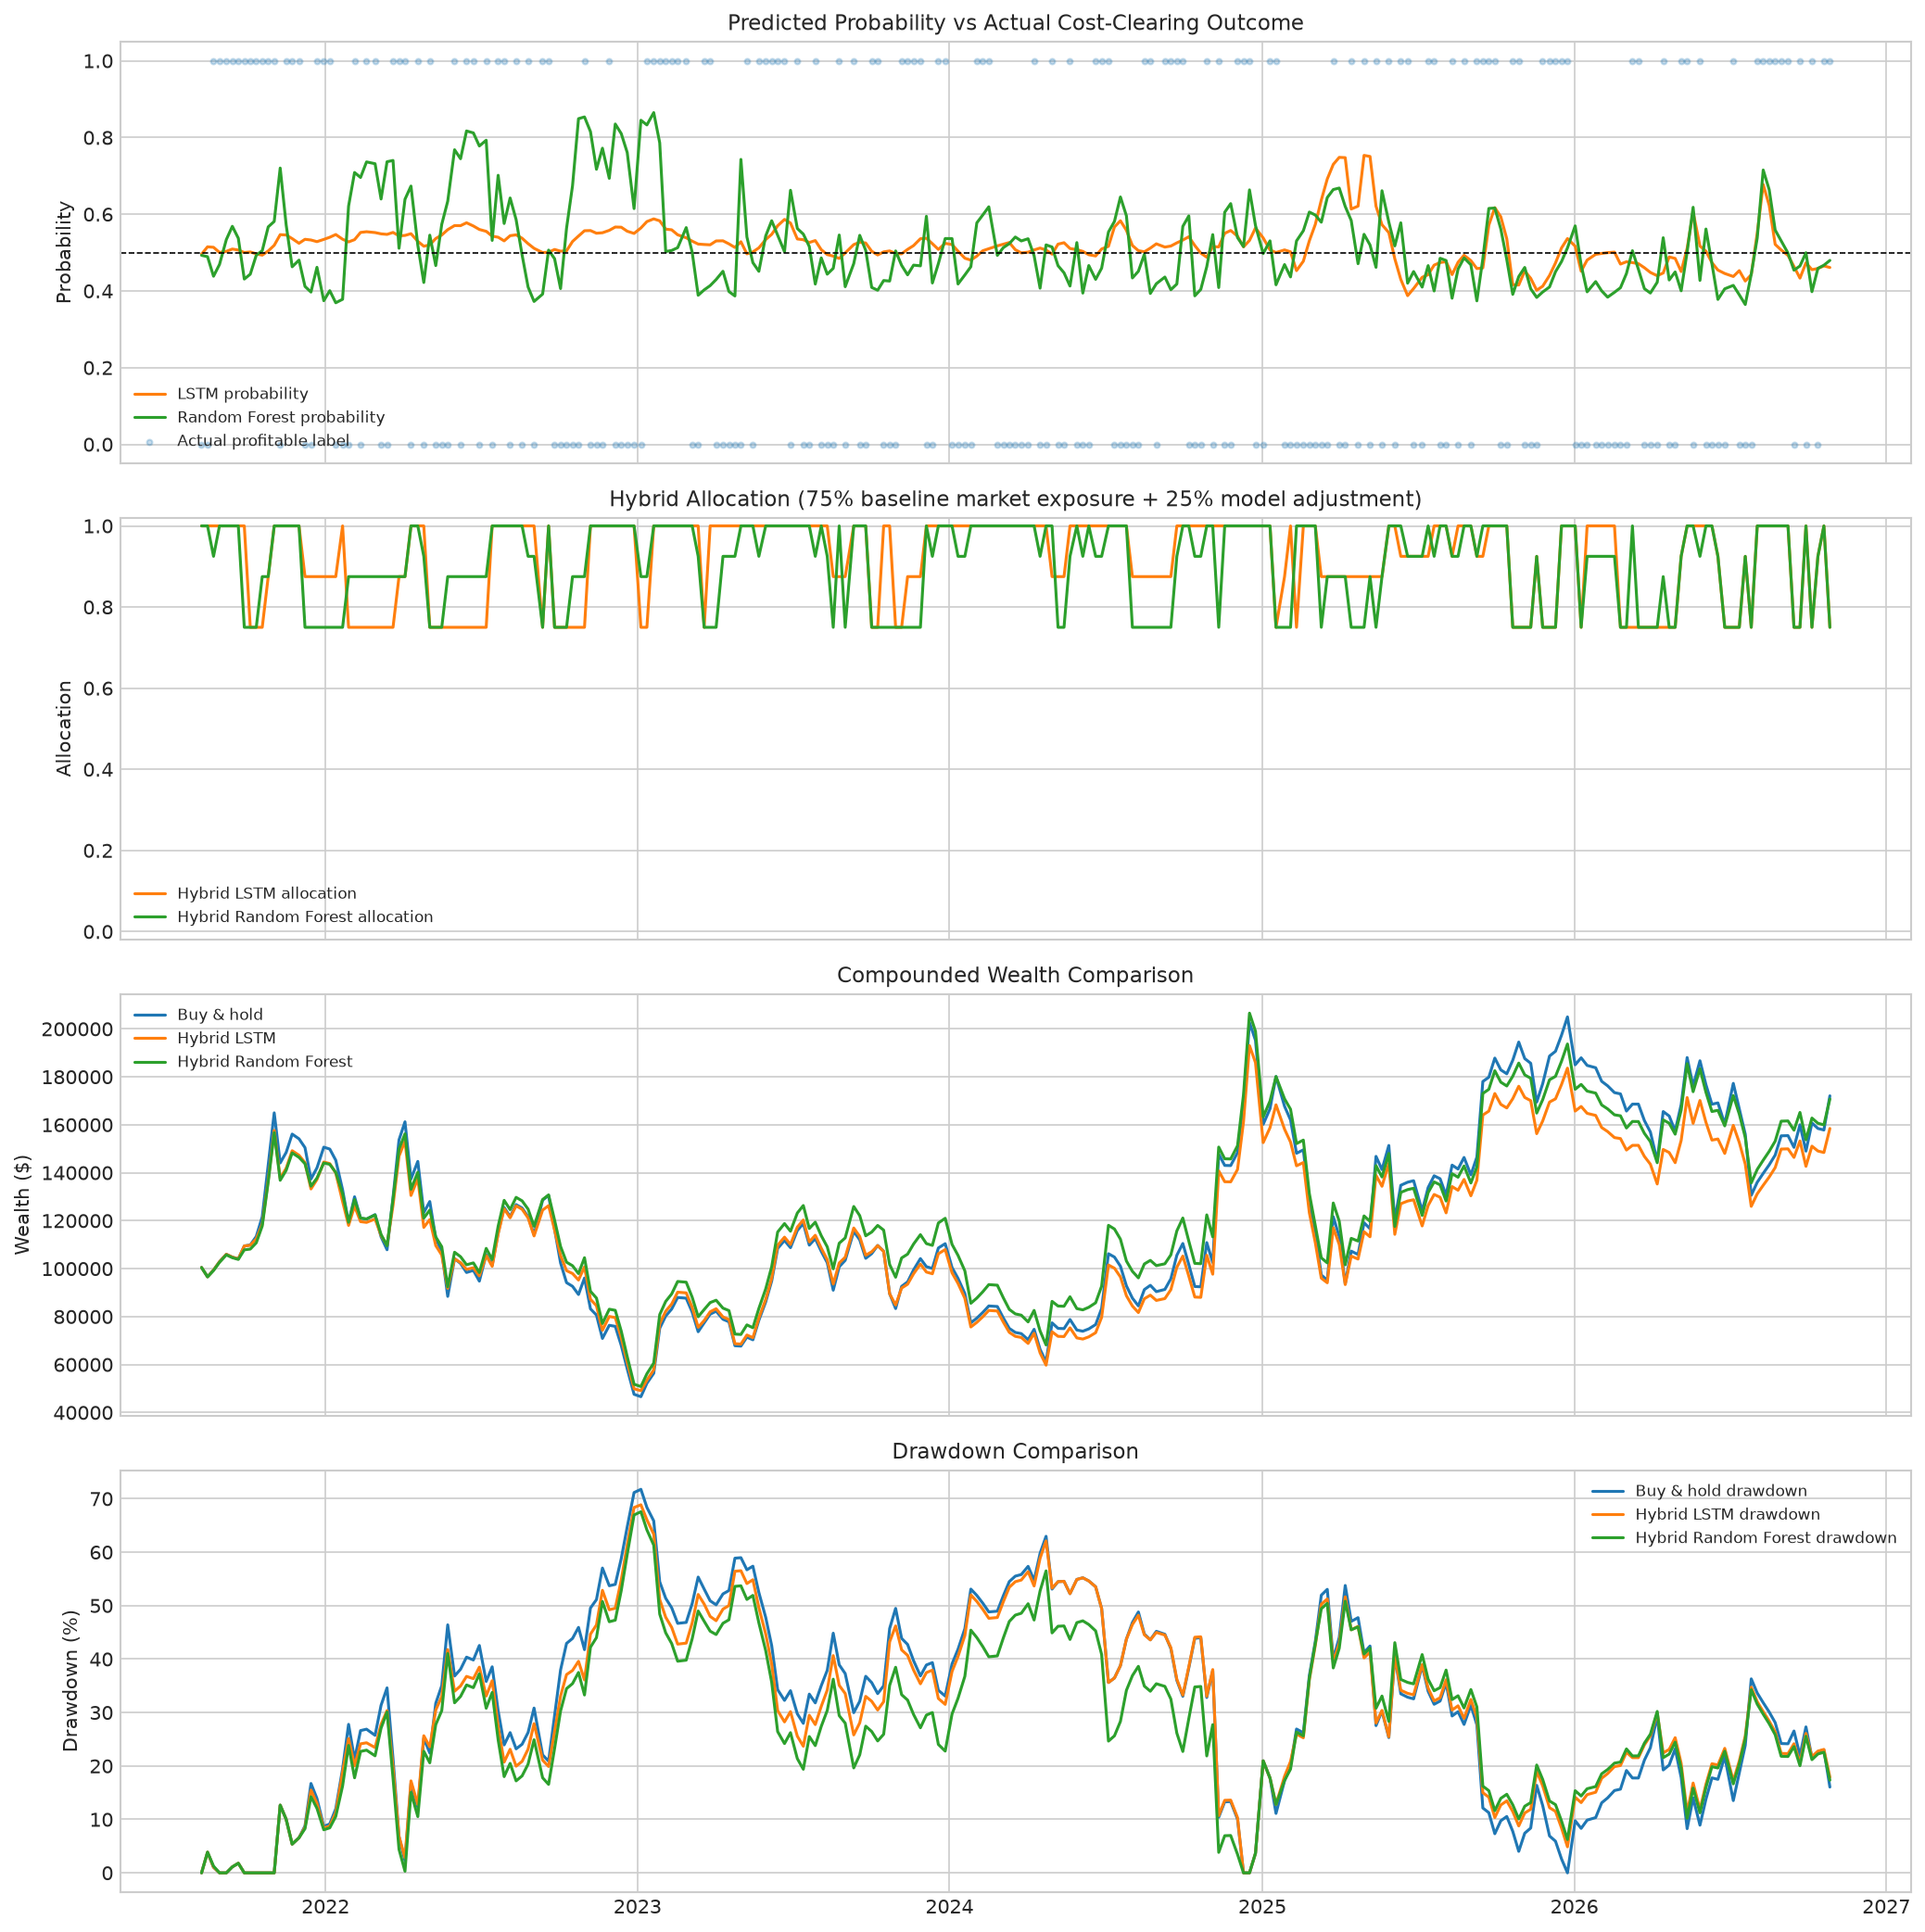


10-day market-relative target


,final wealth,profit,total cost (TC),trades,avg annual return,risk (std dev of return),return per unit of risk,return per unit of downside risk,worst fall from peak,periods with profit,trading frequency,test splits
LSTM,"183,025.87","83,025.87","3,288.32",24.00,12.23%,51.09%,0.39,0.67,48.92%,42.42%,18.18%,3.00
Random Forest,"119,316.84","19,316.84","3,484.26",33.00,3.43%,44.05%,0.20,0.32,60.24%,31.82%,25.61%,3.00
Hybrid LSTM (passive + model),"191,440.65","91,440.65",874.74,6.00,13.20%,57.04%,0.41,0.73,65.16%,47.73%,5.11%,3.00
Hybrid RF (passive + model),"173,811.37","73,811.37","1,187.70",9.00,11.13%,55.16%,0.38,0.66,67.37%,47.73%,6.97%,3.00
Buy & hold,"186,836.38","86,836.38",100.00,1.00,12.67%,60.22%,0.41,0.73,69.95%,47.73%,0.76%,3.00
Momentum (20-day trend),"194,070.32","94,070.32","4,748.42",40.00,13.49%,46.19%,0.40,0.77,57.14%,25.76%,30.30%,3.00


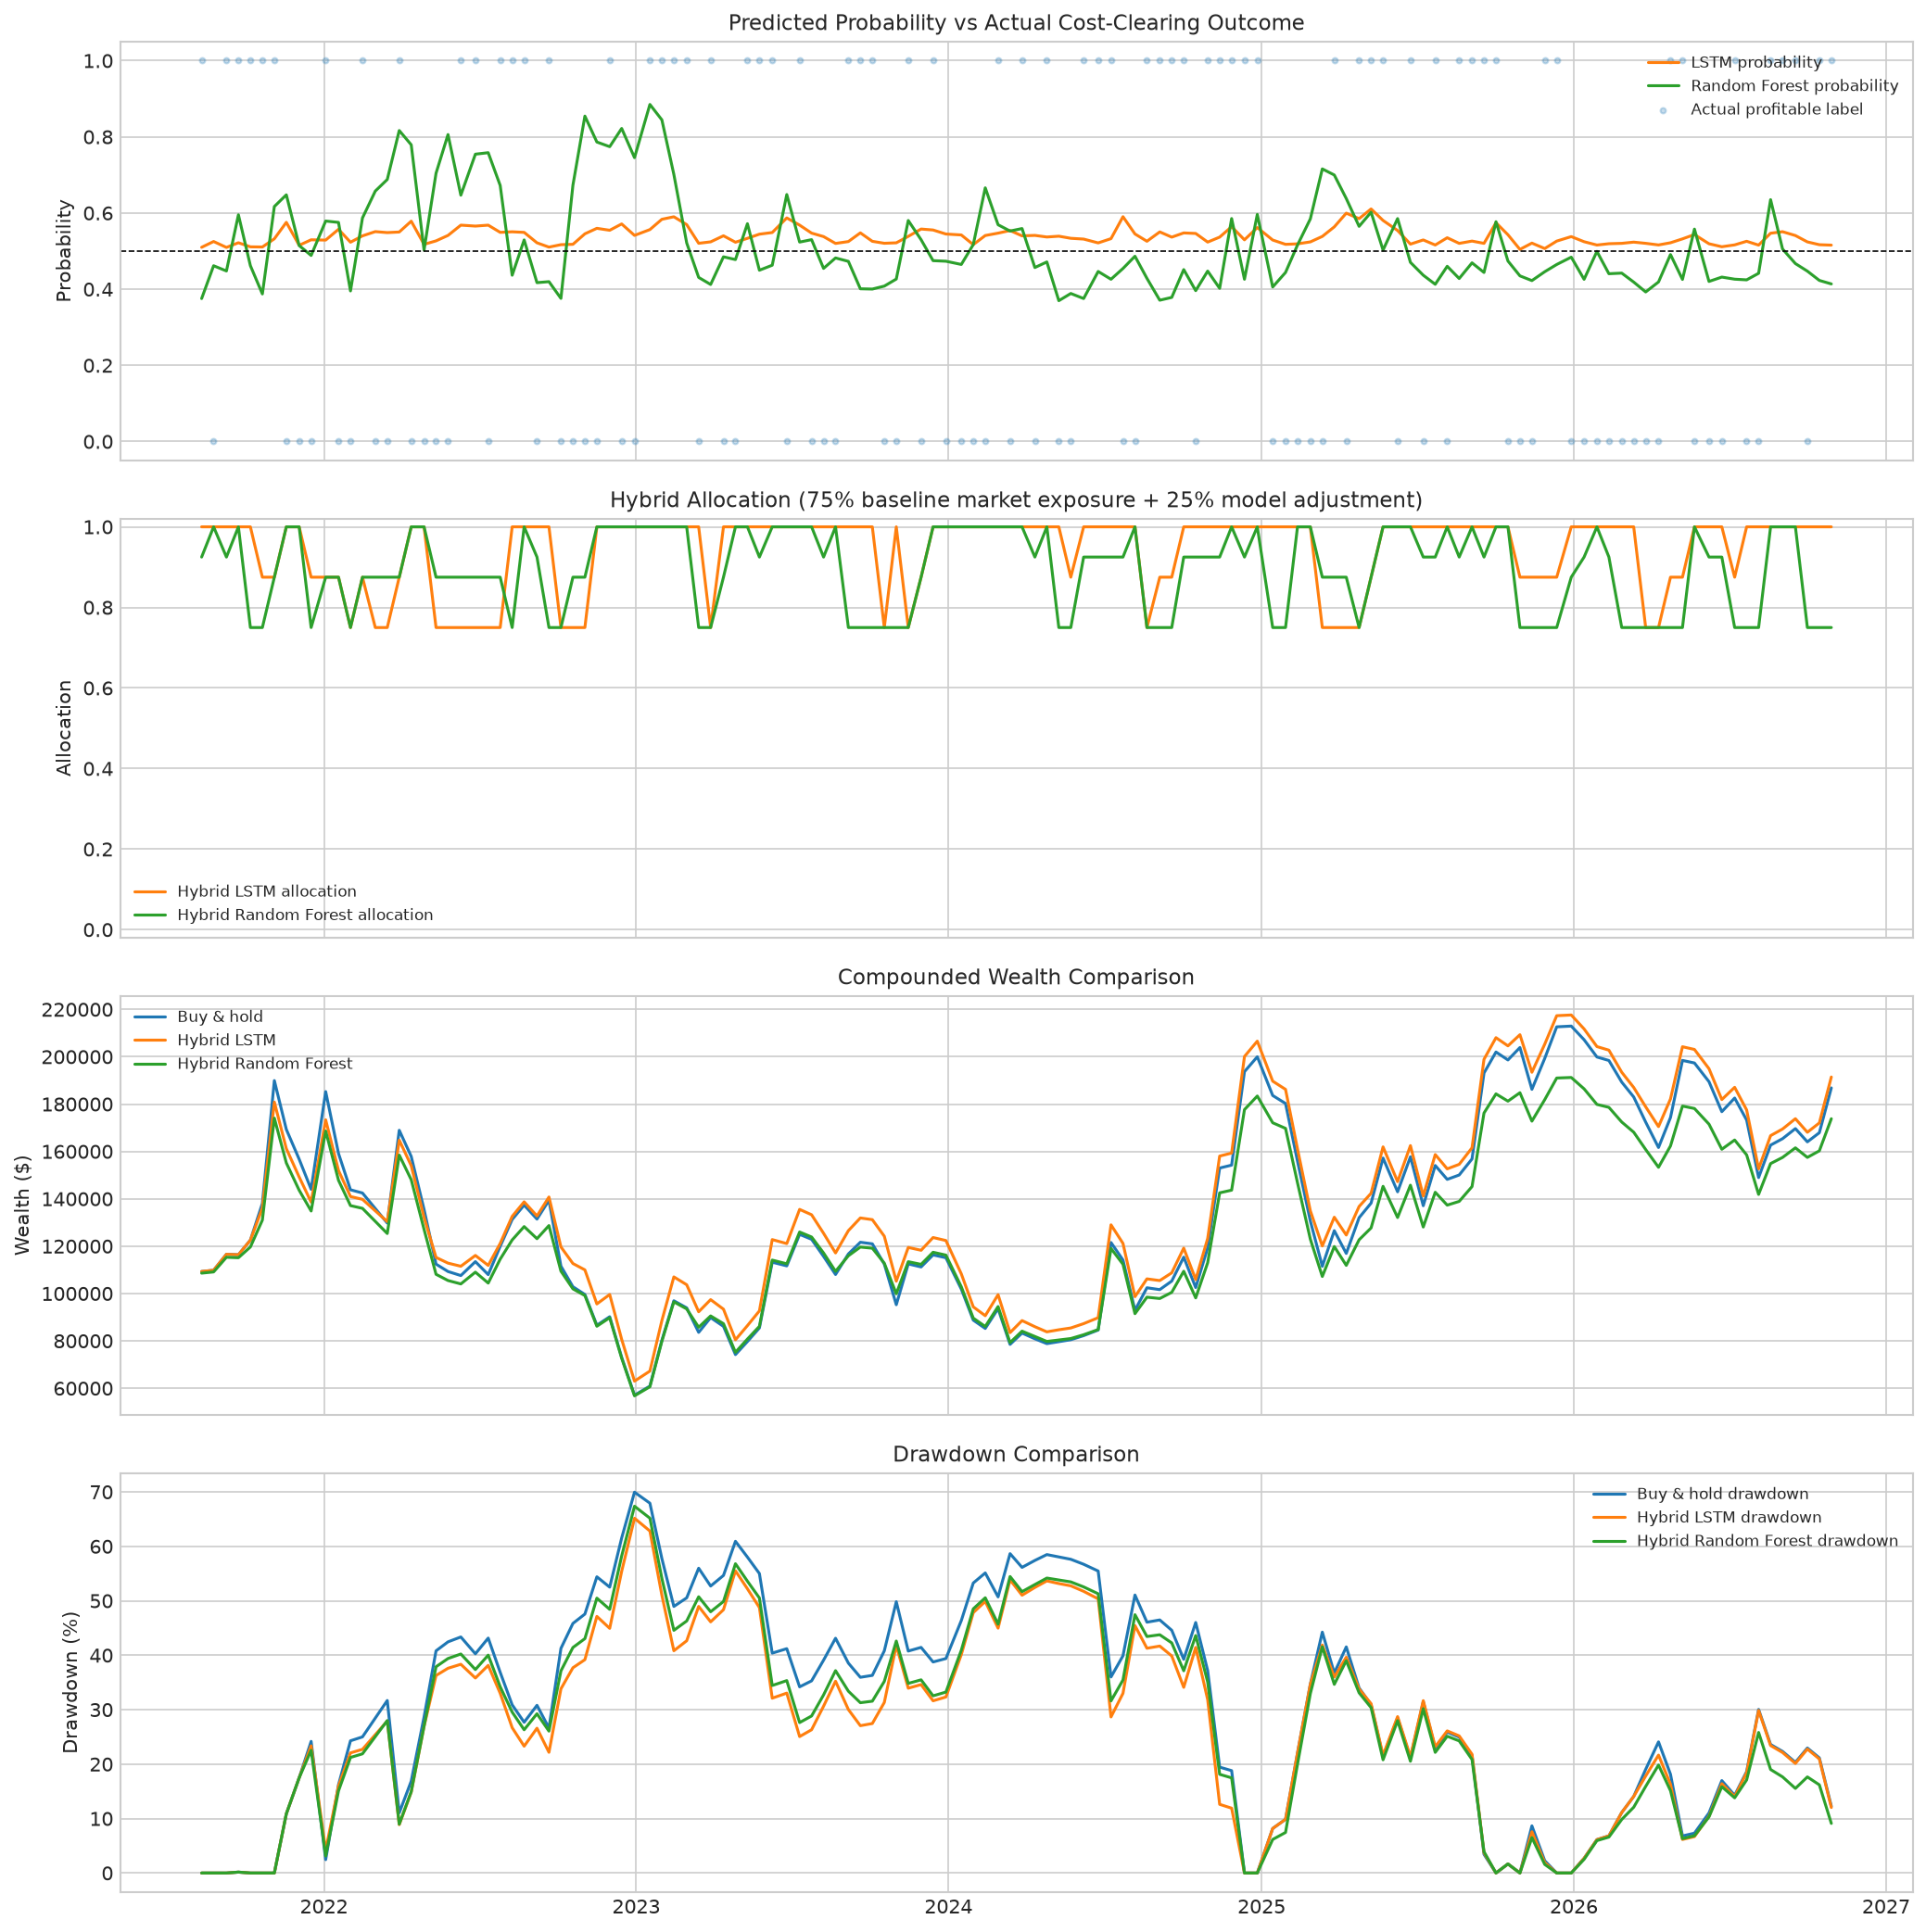

In [34]:
hit_dir = float(np.mean(np.sign(pred_returns) == np.sign(actual_returns)))
up_ratio = float(np.mean(actual_returns > 0))

train_data = dataset.iloc[:split_idx]
shortage_ret = train_data.loc[train_data["excess_demand"] > 0, "target"].mean() * 100
surplus_ret = train_data.loc[train_data["excess_demand"] < 0, "target"].mean() * 100

from scipy import stats
# regression of next-day return on excess demand: target = a + b * excess_demand
ed_reg = stats.linregress(train_data["excess_demand"], train_data["target"])

print("=" * 76)
print(f"ECONOMICS PBL REPORT: {stock_label} (Test Days: {len(actual_returns)})")
print("=" * 76)
print("1) DEMAND AND SUPPLY DYNAMICS:")
print(f"   • Next-day return following SHORTAGE : {shortage_ret:+.3f}%")
print(f"   • Next-day return following SURPLUS  : {surplus_ret:+.3f}%")
print(f"   • Regression: next-day return = a + b * excess demand -> b = {ed_reg.slope:.4f}, R^2 = {ed_reg.rvalue ** 2:.4f}, p-value of b = {ed_reg.pvalue:.3f}")
if ed_reg.pvalue >= 0.05:
    print("   • b is not statistically significant at the 5% level, so this alone cant be treated as a real pattern.")
elif ed_reg.slope > 0:
    print("   • Conclusion: Price adjustments adhere to the Law of Supply and Demand.")
else:
    print("   • Conclusion: Rapid market arbitrage balances short-term volume imbalances quickly.")

print("\n2) MACHINE LEARNING REGRESSION BENCHMARK (RMSE & MAE):")
print(f"   • Return RMSE: LSTM {return_rmse_lstm:.4f}% vs Naive {return_rmse_naive:.4f}%")
print(f"   • Return MAE : LSTM {mae(actual_returns, pred_returns)*100:.4f}% vs Naive {mae(actual_returns, 0)*100:.4f}%")
print(f"   • Price RMSE : LSTM {CURRENCY}{price_rmse_lstm:.2f} vs Naive {CURRENCY}{price_rmse_naive:.2f}")
print(f"   • Directional Accuracy: {hit_dir:.1%} (Market upward rate: {up_ratio:.1%})")

print(f"\n3) FIRM ECONOMICS: Revenue, Costs & Profit (Initial Capital: {CURRENCY}{CAPITAL:,}):")
print(f"   {'Strategy':18s}{'Revenue':>12s}{'Cost':>10s}{'Profit':>12s}{'Trades':>8s}{'Final Wealth':>16s}")
for nm, d in [("LSTM Strategy", strat_results), ("Buy & Hold", bh_results)]:
    print(f"   {nm:18s}{CURRENCY}{d['tr']:>11,.0f}{CURRENCY}{d['tc']:>9,.0f}{CURRENCY}{d['profit']:>11,.0f}{d['trades']:>8d}"
          f"{CURRENCY}{d['wealth'][-1]:>15,.0f}")
if strat_results["trades"] > 0:
    print(f"   • Average Revenue per Trade : {CURRENCY}{strat_results['tr'] / strat_results['trades']:,.0f}")
    print(f"   • Marginal Cost per Trade   : {CURRENCY}{CAPITAL * TC_RATE:,.0f}")

print(f"\n4) INVESTOR UTILITY ANALYSIS:")
print(f"   • Net Utility Change (LSTM Strategy) : {du_strat:+.4f} utils")
print(f"   • Net Utility Change (Buy & Hold)    : {du_bh:+.4f} utils")
print("   • Diminishing MU explains why steady, lower-volatility returns are preferred by risk-averse people.")
print("\n5) REGRESSION CHECKS:")
# is the LSTM's error smaller than the naive forecast's error? t-test on the difference of squared errors
se_naive = actual_returns ** 2
se_lstm = (actual_returns - pred_returns) ** 2
tt = stats.ttest_rel(se_naive, se_lstm)
print(f"   • Squared error, naive vs LSTM (t-test on the difference): t = {tt.statistic:.2f}, p = {tt.pvalue:.3f}  (t > 0 means the LSTM error is smaller)")

# does yesterday's return explain today's return? regress r_t on r_(t-1) (training period)
r_series = train_data["price_change"].values
lag_reg = stats.linregress(r_series[:-1], r_series[1:])
print(f"   • Regression r_t = a + b * r_(t-1): b = {lag_reg.slope:.4f}, R^2 = {lag_reg.rvalue ** 2:.4f}, p-value of b = {lag_reg.pvalue:.3f}")

# actual return vs LSTM forecast on the test period: actual = a + b * forecast (perfect forecast would give a = 0, b = 1)
fc_reg = stats.linregress(pred_returns, actual_returns)
print(f"   • Regression actual = a + b * LSTM forecast (test): a = {fc_reg.intercept:.4f}, b = {fc_reg.slope:.3f}, R^2 = {fc_reg.rvalue ** 2:.4f}, p-value of b = {fc_reg.pvalue:.3f}")
print("=" * 76)

# Walk-forward classification: market-relative 5/10-day targets, LSTM, Random Forest, regimes, and risk metrics.
benchmark_symbol = embedded_benchmark_ticker(TICKER)
benchmark_df, _, bench_is_sim = embedded_load_data(benchmark_symbol, START_DATE, END_DATE)
if bench_is_sim:
    # the market-relative target is meaningless on fake benchmark data, so stop instead of silently carrying on
    raise RuntimeError(f"Could not download the benchmark {benchmark_symbol}; got simulated data instead. Check the connection and rerun.")
rf_annual = EMBEDDED_RF_ANNUAL.get(benchmark_symbol, 0.04)
# only the labels shown in the table are renamed, the keys in the results dict stay the same
term_names = {
    "final_wealth": "final wealth", "profit": "profit", "transaction_cost": "total cost (TC)", "trades": "trades",
    "cagr": "avg annual return", "volatility": "risk (std dev of return)",
    "sharpe": "return per unit of risk", "sortino": "return per unit of downside risk",
    "max_drawdown": "worst fall from peak", "win_rate": "periods with profit",
    "turnover": "trading frequency", "folds": "test splits",
}
strategy_names = {
    "lstm": "LSTM", "random_forest": "Random Forest", "hybrid_lstm": "Hybrid LSTM (passive + model)",
    "hybrid_random_forest": "Hybrid RF (passive + model)", "buy_and_hold": "Buy & hold", "momentum": "Momentum (20-day trend)",
}
from IPython.display import Image, display
walk_forward_results = {str(h): embedded_run_walk_forward(raw_df, benchmark_df, CAPITAL, TC_RATE, EPOCHS, h, rf_annual=rf_annual) for h in (5, 10)}
for horizon, result in walk_forward_results.items():
    print(f"\n{horizon}-day market-relative target")
    report = pd.DataFrame(result["walk_forward"]).T
    percentage_columns = ["cagr", "volatility", "max_drawdown", "win_rate", "turnover"]
    # these are stored as fractions, multiply by 100 so the % sign in the table is correct
    for column in percentage_columns:
        if column in report:
            report[column] = report[column] * 100
    currency_columns = ["final_wealth", "profit", "transaction_cost"]
    format_map = {column: "{:,.2f}" for column in report.columns}
    format_map.update({column: "{:,.2f}%" for column in percentage_columns if column in report})
    format_map.update({column: "{:,.2f}" for column in currency_columns if column in report})
    display(report.rename(columns=term_names, index=strategy_names).style
            .format({term_names.get(k, k): v for k, v in format_map.items()}, na_rep="-")
            .set_caption(f"{horizon}-day market-relative performance"))
    diagnostics = result.get("_diagnostics", [])
    if diagnostics:
        embedded_plot_walk_forward_diagnostics(diagnostics, result["walk_forward"], CURRENCY, f"{OUT_DIR}/{horizon}_day_diagnostics.png")
        display(Image(filename=f"{OUT_DIR}/{horizon}_day_diagnostics.png"))  # show the saved figure in the notebook too
    else:
        print("Diagnostics are unavailable in this result. Rerun this cell to refresh the walk-forward results.")


In [35]:
# Investor choice: risk vs return, drawn like consumer choice (indifference curves + budget line)
# numbers come from the 5-day walk-forward table above, nothing new is trained here
import numpy as np
import matplotlib.pyplot as plt

summary5 = walk_forward_results["5"]["walk_forward"]
labels = {"buy_and_hold": "Buy & hold", "lstm": "LSTM", "hybrid_lstm": "Hybrid LSTM",
          "random_forest": "Random Forest", "hybrid_random_forest": "Hybrid RF", "momentum": "Momentum"}
risk = {k: summary5[k]["volatility"] for k in labels}   # std dev of return (fraction)
ret = {k: summary5[k]["cagr"] for k in labels}          # avg annual return (fraction)

A = 3.0  # how much the investor dislikes risk. an assumption used only to draw the curves, change it and the curves move
utility = lambda mu, sd: mu - 0.5 * A * sd ** 2   # more return is good, more risk is bad

# budget line: put a share w of the money in buy & hold and the rest in the safe asset
w = np.linspace(0, 1.3, 100)
bl_risk = w * risk["buy_and_hold"]
bl_ret = rf_annual + w * (ret["buy_and_hold"] - rf_annual)

u_pts = {k: utility(ret[k], risk[k]) for k in labels}
top = max(u_pts, key=u_pts.get)
sd_grid = np.linspace(0, max(risk.values()) * 1.3, 200)

fig, ax = plt.subplots(figsize=(9, 6))
for shift, ls in [(-0.05, ":"), (0.0, "-"), (0.05, "--")]:
    u_level = u_pts[top] + shift
    ax.plot(sd_grid * 100, (u_level + 0.5 * A * sd_grid ** 2) * 100, color="tab:purple", ls=ls, lw=1.3,
            label="Indifference curve through highest point" if shift == 0 else None)
ax.plot(bl_risk * 100, bl_ret * 100, color="tab:green", lw=2, label="Budget line (stock vs safe asset)")
for k in labels:
    ax.scatter(risk[k] * 100, ret[k] * 100, s=60, zorder=5)
    ax.annotate(labels[k], (risk[k] * 100, ret[k] * 100), xytext=(5, 5), textcoords="offset points", fontsize=9)
ax.scatter([0], [rf_annual * 100], color="k", zorder=5)
ax.annotate("Safe asset", (0, rf_annual * 100), xytext=(5, 5), textcoords="offset points", fontsize=9)
ax.set_xlabel("Risk (std dev of return, %)")
ax.set_ylabel("Average annual return (%)")
ax.set_title("Investor choice: indifference curves and budget line (5-day walk-forward results)", fontsize=11)
ax.set_ylim(min(ret.values()) * 100 - 5, max(max(ret.values()), rf_annual) * 100 + 8)
ax.legend(fontsize=8.5)
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/09_investor_choice.png", dpi=150)
plt.show()

print(f"Utility U = return - (A/2) x risk^2, with A = {A}")
for k in sorted(u_pts, key=u_pts.get, reverse=True):
    print(f"   {labels[k]:15s} U = {u_pts[k]:+.4f}")


Utility U = return - (A/2) x risk^2, with A = 3.0
   Momentum        U = -0.1791
   Random Forest   U = -0.2840
   LSTM            U = -0.3881
   Hybrid RF       U = -0.4005
   Hybrid LSTM     U = -0.4409
   Buy & hold      U = -0.5065
